# Joint Subcarrier and Power Allocation in NOMA: Optimal and Approximate Algorithms

 https://github.com/nokia/subcarrier-power-allocation-noma-solver

## Channel Model

In [ ]:
# -*- coding: utf-8 -*-
"""
Created on Tue May  9 15:39:50 2017

@author: lsalaun

© 2020 Nokia
Licensed under Creative Commons Attribution Non Commercial 4.0 International
SPDX-License-Identifier: CC-BY-NC-4.0

"""

import math
import numpy as np
import matplotlib.pyplot as plt

# K : nb users
# L : nb subbands
# Multiplex : max number of users multiplexed on each subcarrier
# Pmax : total max power
# PmaxN : max power per subcarrier
# G : link gains (not normalized) -> array (K,L)
# N : noises

# pi and pi_inv dim = [L]x[K]
# pi[n] : ranking -> user's index
# pi_inv[n] : user's index -> its ranking

# Compute pi and pi_inv
def computePi(G,N):
    # Find K and L
    K = len(G)
    L = len(G[0])
    pi = np.zeros((L,K),dtype=np.int8)
    pi_inv = np.zeros((L,K),dtype=np.int8)

    # G_N gain over noise ratio array, dim = [L]x[K]
    G_N = np.array([ [G[i][n]/N[i*L+n] for i in range(K)] for n in range(L) ])

    # Compute pi
    pi = np.argsort(G_N, axis=1).astype(np.int8)
    pi_inv = np.zeros((L,K), dtype=np.int8)
    for k in range(K):
        for n in range(L):
            pi_inv[n][pi[n][k]] = k

    return pi,pi_inv

# compute the N over G array of dim = [L]x[K]
def computeN_G(G,N):
    # Find K and L
    K = len(G)
    L = len(G[0])
    N_G = np.array([[N[i*L+n]/G[i][n] for i in range(K)] for n in range(L) ])

    return N_G

# compute the N over G array of dim = [K*L]
def computeN_Gvect(G,N):
    # Find K and L
    K = len(G)
    L = len(G[0])
    N_G = np.zeros((K*L))
    for k in range(K):
        for l in range(L):
            N_G[L*k+l] = N[L*k+l]/G[k][l]

    return N_G

# Compute normalized interference plus noise (valid for downlink only)
def NormIplusN_DL(K,L,N_G,pi,pi_inv,p):
    # Normalized interference plus noise vector
    v = np.zeros(K*L)
    for n in range(L):
        for k in range(K):
            # Add normalized noise
            v[k*L+n] += N_G[n][k]
            rank = pi_inv[n][k]
            # Add the normalized interference from user pi[n][rank2] such that rank2 > rank
            for rank2 in range(rank+1,K):
                k2 = pi[n][rank2]
                v[k*L+n] += p[k2*L+n]
    return v

# Compute weighted data rates vector
def computeWeightedR(K,L,N_G,pi,pi_inv,w,W,p):
    v = NormIplusN_DL(K,L,N_G,pi,pi_inv,p)
    C = np.zeros((K,L))
    for u in range(K):
        for f in range(L):
            C[u][f] = W[f]*w[u]*math.log2(1+p[L*u+f]/v[L*u+f])
    return C

# Compute WSR for a single subcarrier
def computeWSR_sc(K,lsub,N_G_l,pi,pi_inv,w,W,p):
    # Normalized interference plus noise vector
    v = np.zeros(K)
    for k in range(K):
        # Add normalized noise
        v[k] += N_G_l[k]
        rank = pi_inv[lsub][k]
        # Add the normalized interference from user pi[lsub][rank2] such that rank2 > rank
        for rank2 in range(rank+1,K):
            k2 = pi[lsub][rank2]
            v[k] += p[k2]

    # compute the WSR of subcarrier lsub
    C = W[lsub]*w*np.log2(1+p/v)
#    print('p',p)
#    print('v',v)
#    print('N_G_l',N_G_l)
#    print(W[lsub]*w*np.log2(1+p/v))
#    print('C',C)
    return C

# Compute WSR for a single subcarrier given:
# x: a power vector x of type X (transformed) with only active users.
# The active users indexes are given by "users"
# users: the list of active users
# This is used in SpeedUpSCUS for faster computation of the wsr (time complexity from K to M)
def computeWSR_sc_X(users,lsub,N_G_l,pi,pi_inv,w,W,x):
    # Number of active users
    M = len(users)
    # Normalized interference plus noise vector
    v = np.zeros(len(users))
    for index_user in range(M-1):
        rank = users[index_user]
        k = pi[lsub][rank]
        # Add normalized noise
        v[index_user] += N_G_l[k]
        # Add the normalized interference from user with index i > index_user and i < M-1
        for i in range(index_user+1,M-1):
            v[index_user] +=  x[i] - x[i+1]
        # Last element
        v[index_user] +=  x[M-1]

    # Last decoded user (best user)
    rank = users[M-1]
    k = pi[lsub][rank]
    # Add normalized noise
    v[M-1] += N_G_l[k]

    # compute the WSR of subcarrier lsub
    C = np.zeros(M)
    for index_user in range(M-1):
        rank = users[index_user]
        k = pi[lsub][rank]
        C[index_user] = W[lsub]*w[k]*np.log2(1+(x[index_user]-x[index_user+1])/v[index_user])
    rank = users[M-1]
    k = pi[lsub][rank]
    C[M-1] = W[lsub]*w[k]*np.log2(1+x[M-1]/v[M-1])

#    print('v',v)
#    print('C',C)
    return C

########################################### SCPC and SCUS algorithms ###########################################

# Convert x (of size [L]x[K]) to p of size [K*L]
def X2P(x,pi,K,L):
    p = np.zeros(K*L)
    for l in range(L):
        # p_{pi^n(i)} = x_i^l - x_{i+1}^l
        for i in range(K-1):
            p[pi[l,i]*L+l] = x[l][i] - x[l][i+1]
        # Last element
        p[pi[l,K-1]*L+l] = x[l][K-1]
    return p

def X2P_sc(x,pi,K,lsub):
    p = np.zeros(K)
    # p_{pi^n(i)} = x_i^l - x_{i+1}^l
    for i in range(K-1):
        p[pi[lsub,i]] = x[i] - x[i+1]
    # Last element
    p[pi[lsub,K-1]] = x[K-1]
    return p

# Convert short active X list to X
def activeX2X_sc(active_x,active_users,pi,K,lsub):
    x = np.zeros(K)
    for index in range(len(active_x)-1,-1,-1):
        x[0:active_users[index]+1] = active_x[index]
    return x


# Maximize f_i,j^l
# l : considered subcarrier
# P is the max allocated power budget
# w : weights
# W : subcarrier's bandwidth
# N_G_l : N/G only restrict to subcarrier l (column l)
def MaxF(j,i,l,N_G_l,pi,P,w):
    a = pi[l][i]
    b = pi[l][j-1]
    if j == 0 or w[a] >= w[b]:
        return P
    else:
        return max(0,min((w[b]*N_G_l[a]-w[a]*N_G_l[b])/(w[a]-w[b]),P))

# Evaluate f_i,j^l
def F(x,j,i,l,N_G_l,pi,w,W):
    a = pi[l][i]
    b = pi[l][j-1]
    if j == 0:
        return W[l]*w[a]*math.log2(x+N_G_l[a])
    elif j > i:
        return 0
    else:
        return   W[l]*(w[a]*math.log2(x+N_G_l[a])-w[b]*math.log2(x+N_G_l[b]))

# Evaluate the derivative of f_i,j^l with respect to x
def F_deriv(x,j,i,l,N_G_l,pi,w,W):
    a = pi[l][i]
    b = pi[l][j-1]
    if j == 0:
        return W[l]/math.log(2)*w[a]/(x+N_G_l[a])
    elif j > i:
        return 0
    else:
        return   W[l]/math.log(2)*(w[a]/(x+N_G_l[a])-w[b]/(x+N_G_l[b]))

# SCPC : single-carrier power control
# lsub : current subcarrier
# ksub : subset of users (i.e., active users)
# P : current subcarrier max power allocation
def SCPC(K,P,N_G_l,lsub,ksub,pi,pi_inv,w,W):
    # Convert ksub to their ranking (decoding order) vector x_index
    x_index = np.sort(pi_inv[lsub,ksub])
    # Vector of x of length K
    x = np.zeros(K)
    for index in range(len(x_index)):
        i = x_index[index]
        x_star = MaxF(i,i,lsub,N_G_l,pi,P,w)
        index2 = index-1
        j = x_index[index2]

        while index2 >= 0 and x[j]<x_star:
            x_star = MaxF(j,i,lsub,N_G_l,pi,P,w)
            index2 = index2-1
            j = x_index[index2]

        x[j+1:i+1] = x_star

    return x

# SCPC with bar plot for testing or demoing
def SCPC_barplot(K,P,N_G_l,lsub,ksub,pi,pi_inv,w,W):
    # Convert ksub to their ranking (decoding order) vector x_index
    x_index = np.sort(pi_inv[lsub,ksub])
    # Vector of x of length K
    x = np.zeros(K)
    for index in range(len(x_index)):
        i = x_index[index]
        x_star = MaxF(i,i,lsub,N_G_l,pi,P,w)
        index2 = index-1
        j = x_index[index2]

        print('\n---------------- Step i =',i,'----------------')

        # TEST
        x[i] = x_star
        plt.bar(np.arange(K), x, color="blue")
        plt.show()
        print('x =',x)
        # TEST

        while index2 >= 0 and x[j]<x_star:
            print('\n---------------- Step i =',i,'----------------')
            print('----------- Backtracking step j =',j,'-----------')
            x_star = MaxF(j,i,lsub,N_G_l,pi,P,w)
            index2 = index2-1
            j = x_index[index2]

            # TEST
            x[j+1:i+1] = x_star
            plt.bar(np.arange(K), x, color="blue")
            plt.show()
            print('x =',x)
            # TEST

        x[j+1:i+1] = x_star

    return x

# F^n derivative with respect to P
# x : result of SCPC (or SCUS) with input P for subcarrier l
# l : current subcarrier
def Fn_derivP(K,P,x,l,N_G_l,pi,w,W):
    j = 0
    i = 0
    while i+1<K and x[i+1] == P:
        i += 1

    return F_deriv(P,j,i,l,N_G_l,pi,w,W)

# SCUS_first2last : single-carrier user selection (dynamic programming) from the Infocom paper
# Going from first decoded user (index 1) to last decoded user (index K)
# lsub : current subcarrier
# P : current subcarrier max power allocation
def SCUS_first2last(K,Multiplex,P,N_G_l,lsub,pi,w,W):

    # Initialize table V, T
    V = np.zeros((Multiplex,K,K))
    X = np.zeros((Multiplex,K,K))
    T = np.zeros((Multiplex,K,K,3),dtype=np.int8)
    for i in range(K):
        V[0,0,i] = F(P,0,i,lsub,N_G_l,pi,w,W) + F(0,i+1,K-1,lsub,N_G_l,pi,w,W)
        X[0,0,i] = P
        T[0,0,i,:] = -1*np.ones(3,dtype=np.int8)
    for j in range(1,K):
        for i in range(j,K):
            to_P = F(P,0,i,lsub,N_G_l,pi,w,W) + F(0,i+1,K-1,lsub,N_G_l,pi,w,W)
            to_0 = V[0,j-1,j-1]
            if to_P >= to_0:
                V[0,j,i] = to_P
                X[0,j,i] = P
                T[0,j,i,:] = np.array([0,0,i],dtype=np.int8)
            else:
                V[0,j,i] = to_0
                X[0,j,i] = 0
                T[0,j,i,:] = np.array([0,j-1,j-1],dtype=np.int8)
    for m in range(1,Multiplex):
        for i in range(K):
            V[m,0,i] = V[0,0,i]
            X[m,0,i] = X[0,0,i]
            T[m,0,i,:] = -1*np.ones(3,dtype=np.int8)

    # Iterates
    for j in range(1,K):
        for m in range(1,Multiplex):
            # Update
            # v1 : cas ou j~i est indep. de 0,..,j-1
            # v2 : cas ou j~i est intégré à 0,..,j-1
            for i in range(j,K):
                x = MaxF(j,i,lsub,N_G_l,pi,P,w)
                v0 = V[m,j-1,j-1]
                if x >= X[m-1,j-1,j-1] or x<=0:
                    v1 = -math.inf
                else:
                    v1 = V[m-1,j-1,j-1] + F(x,j,i,lsub,N_G_l,pi,w,W) - F(0,j,i,lsub,N_G_l,pi,w,W)
                v2 = V[m,j-1,i]
                # Update
                if v1 > v2 and v1 > v0:
                    V[m,j,i] = v1
                    X[m,j,i] = x
                    T[m,j,i,:] = np.array([m-1,j-1,j-1],dtype=np.int8)
                elif v2 > v0:
                    V[m,j,i] = v2
                    X[m,j,i] = X[m,j-1,i]
                    T[m,j,i,:] = np.array([m,j-1,i],dtype=np.int8)
                else:
                    V[m,j,i] = v0
                    X[m,j,i] = 0
                    T[m,j,i,:] = np.array([m,j-1,j-1],dtype=np.int8)

    # Retrieve the best allocation from V, X, T
    x = np.zeros(K)
    m = Multiplex-1
    i = 0
    valmax = -math.inf
    for l in range(K):
        if valmax <= V[m,l,l]:
            valmax = V[m,l,l]
            i = l
    j = i
    while True:
        x[j:i+1] = X[m,j,i]
        if T[m,j,i,0] == -1:
            break
        newT = T[m,j,i,:]
        m = newT[0]
        j = newT[1]
        i = newT[2]

#    print(V[Multiplex-1,:,:])

    return x

# SCUS_last2first : single-carrier user selection (dynamic programming) from the TSP paper
# Going from last decoded user (index K) to first decoded user (index 1)
# lsub : current subcarrier
# P : current subcarrier max power allocation
def SCUS_last2first(K,Multiplex,P,N_G_l,lsub,pi,w,W):

    # Initialize table V, T
    V = np.zeros((Multiplex+1,K,K))
    X = np.zeros((Multiplex+1,K,K))
    T = np.zeros((Multiplex+1,K,K,3),dtype=np.int8)

    # Initialization ----------------------------------------------------------------------
    # Multiplex = 0 means no active users (every x = 0)
    for i in range(K-1,-1,-1):
        for j in range(i,-1,-1):
            V[0,j,i] = F(0,j,K-1,lsub,N_G_l,pi,w,W)
            X[0,j,i] = 0
            T[0,j,i,:] = -1*np.ones(3,dtype=np.int8)
    for m in range(1,Multiplex+1):
        for j in range(K-1,-1,-1):
            x_opt = MaxF(j,K-1,lsub,N_G_l,pi,P,w)
            V[m,j,K-1] = F(x_opt,j,K-1,lsub,N_G_l,pi,w,W)
            X[m,j,K-1] = x_opt
            T[m,j,K-1,:] = -1*np.ones(3,dtype=np.int8)

    # Iteration ----------------------------------------------------------------------
    for i in range(K-2,-1,-1):
        for m in range(1,Multiplex+1):
            for j in range(i,-1,-1):
                x_opt = MaxF(j,i,lsub,N_G_l,pi,P,w)
                V_if_i_active = F(x_opt,j,i,lsub,N_G_l,pi,w,W)+V[m-1,i+1,i+1]
                V_if_i_inactive = V[m,j,i+1]
                if V_if_i_active > V_if_i_inactive and x_opt > X[m-1,i+1,i+1]:
                    V[m,j,i] = V_if_i_active
                    X[m,j,i] = x_opt
                    T[m,j,i,:] = np.array([m-1,i+1,i+1],dtype=np.int8)
                else:
                    V[m,j,i] = V_if_i_inactive
                    X[m,j,i] = X[m,j,i+1]
                    T[m,j,i,:] = np.array([m,j,i+1],dtype=np.int8)

    # Retrieve the best allocation from V, X, T
    x = np.zeros(K)
    m = Multiplex
    i = 0
    j = 0
    while True:
        x[j:i+1] = X[m,j,i]
        if T[m,j,i,0] == -1:
            break
        newT = T[m,j,i,:]
        m = newT[0]
        j = newT[1]
        i = newT[2]

    return x

########################################### Grad_JSPA and eqPow_JSPA algorithm ###########################################

# This class contains a speed up version of SCUS when it is called multiple times
# on the same subcarrier with differente power budget P
class SpeedUpSCUS:
    # When the object is instantiate, SCUS is called once for budget Pmax (max possible power budget on this subcarrier)
    # then at most K users selections (power vector x) are kept in self.users_selections to later speed up the single-carrier user selectiona and power allocation
    # In later use, SCUS can be simplified and computed in O(MK) (see method speedUp_SCUS)
    def __init__(self,K,Multiplex,Pmax,N_G_l,lsub,pi,pi_inv,w,W):
        self.K = K
        self.lsub = lsub
        self.Multiplex = Multiplex
        self.Pmax = Pmax
        self.N_G_l = N_G_l
        self.pi = pi
        self.pi_inv = pi_inv
        self.w = w
        self.W = W

        #---------------- Below is equivalent to SCUS_last2first(K,Multiplex,Pmax,N_G_l,lsub,pi,w,W) ----------------
        # Initialize table V, T
        V = np.zeros((Multiplex+1,K,K))
        X = np.zeros((Multiplex+1,K,K))
        T = np.zeros((Multiplex+1,K,K,3),dtype=np.int8)

        # Initialization ----------------------------------------------------------------------
        # Multiplex = 0 means no active users (every x = 0)
        for i in range(K-1,-1,-1):
            for j in range(i,-1,-1):
                V[0,j,i] = F(0,j,K-1,lsub,N_G_l,pi,w,W)
                X[0,j,i] = 0
                T[0,j,i,:] = -1*np.ones(3,dtype=np.int8)
        for m in range(1,Multiplex+1):
            for j in range(K-1,-1,-1):
                x_opt = MaxF(j,K-1,lsub,N_G_l,pi,Pmax,w)
                V[m,j,K-1] = F(x_opt,j,K-1,lsub,N_G_l,pi,w,W)
                X[m,j,K-1] = x_opt
                T[m,j,K-1,:] = -1*np.ones(3,dtype=np.int8)

        # Iteration ----------------------------------------------------------------------
        for i in range(K-2,-1,-1):
            for m in range(1,Multiplex+1):
                for j in range(i,-1,-1):
                    x_opt = MaxF(j,i,lsub,N_G_l,pi,Pmax,w)
                    V_if_i_active = F(x_opt,j,i,lsub,N_G_l,pi,w,W)+V[m-1,i+1,i+1]
                    V_if_i_inactive = V[m,j,i+1]
                    if V_if_i_active > V_if_i_inactive and x_opt > X[m-1,i+1,i+1]:
                        V[m,j,i] = V_if_i_active
                        X[m,j,i] = x_opt
                        T[m,j,i,:] = np.array([m-1,i+1,i+1],dtype=np.int8)
                    else:
                        V[m,j,i] = V_if_i_inactive
                        X[m,j,i] = X[m,j,i+1]
                        T[m,j,i,:] = np.array([m,j,i+1],dtype=np.int8)

        # Retrieve the best allocation for V[Multiplex,j,i] with i = 0..K-1 and j = 0
        # Store the corresponding power vector x in list_power_vectors
        list_power_vectors = np.zeros((K,K))
        for i_init in range(K):
            m = Multiplex
            i = i_init
            j = 0
            while True:
                list_power_vectors[i_init,j:i+1] = X[m,j,i]
                if T[m,j,i,0] == -1:
                    break
                newT = T[m,j,i,:]
                m = newT[0]
                j = newT[1]
                i = newT[2]

        # Only keep the power vectors that are differents
        # i.e. remove redundant power vectors in the list
        list_power_vectors = np.unique(list_power_vectors, axis=0)
        # Format list_power_vectors by keeping only the active users' power
        # and store their index in list_active_users
        self.list_power_vectors = [None] * len(list_power_vectors)
        self.list_active_users = [None] * len(list_power_vectors)
        for index in range(len(list_power_vectors)):
#            print(index)
            power_vector = list_power_vectors[index]
            active_users = []
            active_power_vector = []
            user_pt = 0
            while user_pt < len(power_vector):
                while user_pt+1 < len(power_vector) and power_vector[user_pt+1]==power_vector[user_pt]:
                    user_pt += 1
                active_users.append(user_pt)
                active_power_vector.append(power_vector[user_pt])
                user_pt += 1
            # Remove last power if it's equal to zero
            if active_power_vector[-1] == 0:
                active_users.pop()
                active_power_vector.pop()

            self.list_power_vectors[index] = np.array(active_power_vector)
            self.list_active_users[index] = np.array(active_users,dtype=int)

        #---------------- End of SCUS_last2first ----------------

    # speedUp_SCUS, uses list_power_vectors to simplify the calculation
    # P is the current power budget, P should be less than or equal to Pmax
    def speedUp_SCUS(self, P):
        # Find which power allocation is best
        best_x = np.minimum(self.list_power_vectors[0],P*np.ones(self.list_power_vectors[0].shape))
        best_wsr = np.sum(computeWSR_sc_X(self.list_active_users[0],self.lsub,self.N_G_l,self.pi,self.pi_inv,self.w,self.W,best_x))
        best_index = 0
        for i in range(1,len(self.list_power_vectors)):
            curr_x = np.minimum(self.list_power_vectors[i],P*np.ones(self.list_power_vectors[i].shape))
            curr_wsr = np.sum(computeWSR_sc_X(self.list_active_users[i],self.lsub,self.N_G_l,self.pi,self.pi_inv,self.w,self.W,curr_x))
            if curr_wsr > best_wsr:
                best_x = curr_x
                best_wsr = curr_wsr
                best_index = i

        # get the full description X (with all users: actives and inactives)
#        print('ground truth SCUS',SCUS_last2first(self.K,self.Multiplex,P,self.N_G_l,self.lsub,self.pi,self.w,self.W))
#        print('best short X',best_x)
#        print('avtice users',self.list_active_users[best_index])
        best_x = activeX2X_sc(best_x,self.list_active_users[best_index],self.pi,self.K,self.lsub)
#        print('best_x',best_x)
        best_p = X2P_sc(best_x,self.pi,self.K,self.lsub)
#        print('best_p',best_p)
        best_wsr = computeWSR_sc(self.K,self.lsub,self.N_G_l,self.pi,self.pi_inv,self.w,self.W,best_p)

        return best_x, best_p, best_wsr

    # Same as speedUp_SCUS, but only returns the wsr (the scalar, not the vector)
    def speedUp_SCUS_onlyWSR(self, P):
        # Find which power allocation is best
        best_x = np.minimum(self.list_power_vectors[0],P*np.ones(self.list_power_vectors[0].shape))
        best_wsr = np.sum(computeWSR_sc_X(self.list_active_users[0],self.lsub,self.N_G_l,self.pi,self.pi_inv,self.w,self.W,best_x))
        for i in range(1,len(self.list_power_vectors)):
            curr_x = np.minimum(self.list_power_vectors[i],P*np.ones(self.list_power_vectors[i].shape))
            curr_wsr = np.sum(computeWSR_sc_X(self.list_active_users[i],self.lsub,self.N_G_l,self.pi,self.pi_inv,self.w,self.W,curr_x))
            if curr_wsr > best_wsr:
                best_x = curr_x
                best_wsr = curr_wsr

        return best_wsr

########################################### Grad_JSPA and eqPow_JSPA algorithm ###########################################

# Function to minimize by Grad_JSPA
# Pvect : vector of each subcarriers' power budget to be optimized
# Output : function value, gradient
def fun_first2last(Pvect,K,L,Multiplex,N_G,pi,pi_inv,w,W):
    x = np.zeros((L,K))
    for lsub in range(L):
        x[lsub] = SCUS_first2last(K,Multiplex,Pvect[lsub],N_G[lsub],lsub,pi,w,W)
    p = X2P(x,pi,K,L)

    # Compute the gradient
    grad = np.zeros(L)
    for l in range(L):
#        print(Fn_derivP(K,Pvect[l],x[l],l,N_G[l],pi,w,W))
        grad[l] = Fn_derivP(K,Pvect[l],x[l],l,N_G[l],pi,w,W)

#    print('Pvect',Pvect)
#    print('funval',-np.sum(computeWeightedR(K,L,N_G,pi,pi_inv,w,W,p)))
#    for l in range(L):
#        print([p[k*L+l] for k in range(K)])
#    print('grad',-grad)

    return -np.sum(computeWeightedR(K,L,N_G,pi,pi_inv,w,W,p)), -grad

# Function to minimize by Grad_JSPA
# Uses the speed up SpeedUpSCUS procedure
# suSCUS : List of initialized SpeedUpSCUS objects, one for each subcarrier
# Pvect : vector of each subcarriers' power budget to be optimized
# Output : function value, gradient
def fun_last2first(Pvect,suSCUS,K,L,Multiplex,N_G,pi,pi_inv,w,W):
    x = np.zeros((L,K))
    wsr = np.zeros((L,K))
    for lsub in range(L):
        x[lsub], _, wsr[lsub] = suSCUS[lsub].speedUp_SCUS(Pvect[lsub])

    # Compute the gradient
    grad = np.zeros(L)
    for l in range(L):
#        print(Fn_derivP(K,Pvect[l],x[l],l,N_G[l],pi,w,W))
        grad[l] = Fn_derivP(K,Pvect[l],x[l],l,N_G[l],pi,w,W)

#    print('Pvect',Pvect)
#    print('funval',-np.sum(computeWeightedR(K,L,N_G,pi,pi_inv,w,W,p)))
#    for l in range(L):
#        print([p[k*L+l] for k in range(K)])
#    print('grad',-grad)

    return -np.sum(wsr), -grad

# Function to get the weighted sum rate given Pvect
# this function calls SCUS_first2last
def F_Pvect_first2last(Pvect,K,L,Multiplex,N_G,pi,pi_inv,w,W):
    x = np.zeros((L,K))
    for lsub in range(L):
        x[lsub] = SCUS_first2last(K,Multiplex,Pvect[lsub],N_G[lsub],lsub,pi,w,W)
#    print(x)
    p = X2P(x,pi,K,L)
#    print(p)
#    for l in range(L):
#        print([p[k*L+l] for k in range(K)])

    return computeWeightedR(K,L,N_G,pi,pi_inv,w,W,p)

# Projection of P on the simplex with sum P <= Pmax
def proj(P,Pmax):
    return P*Pmax/np.sum(P)

# Grad_JSPA : multi-carrier power control -> projected gradient on top of SCUS
# Backtracking line search is used to tune the step size at each iteration
# l : current subcarrier
# Pmax : total power budget
# PmaxN : max power per subcarrier
# delta : variable precision at termination
# max_iters : maximum number of iterations (100 by default)
# rounding_step : if not None, then the best solution found is rounded to the nearest multiple of
#                 rounding_step. i.e., the per subcarrier power allocation is discretized to
#                 take value of the form l*rounding_step, where l=0..floor(Pmax/rounding_step)
# Output: best power allocation per subcarrier found, corresponding objective function value (WSR),
#         number of iterations performed by the gradient
def Grad_JSPA(K,L,Multiplex,Pmax,N_G,pi,pi_inv,w,W,delta,max_iters=100,rounding_step=None):
    # Initial value
    P0 = Pmax/L*np.ones(L)

    # Projected gradient descent
    previous_step_size = math.inf
    iters = 0       # Iteration counter
    countSCUS = 0   # Number of SCUS calls

    # cur_fun: function evaluation, cur_grad: gradient evaluation
    # best_fun: best value of the objective function found so far
    cur_x = P0 # Starting point
    cur_fun = 0
    best_fun = 0
    best_x = P0
    cur_grad = 0

    while (previous_step_size > delta) & (iters < max_iters):
        # Evaluate fun and its gradient
        res = fun_first2last(cur_x,K,L,Multiplex,N_G,pi,pi_inv,w,W)
        cur_fun = -res[0]
        cur_grad = -res[1]
        countSCUS += L
#        print(res)

        # Keep the best value and its variable
        if cur_fun > best_fun:
            best_fun = cur_fun
            best_x = cur_x

        # Backtracking line search until the Armijo–Goldstein condition is satisfied
        m = np.dot(cur_grad,cur_grad)/np.linalg.norm(cur_grad,ord=1)
        c = delta   # Armijo–Goldstein condition parameter
        tau = 0.5   # alpha decreasing rate
        # Initial step size in the backtracking line search method
        alpha = Pmax*15 / np.linalg.norm(cur_grad,ord=1)
        while True:
            test_x = proj( cur_x + alpha * cur_grad , Pmax)
            res = fun_first2last(test_x,K,L,Multiplex,N_G,pi,pi_inv,w,W)
            test_fun = -res[0]
            countSCUS += L
            if test_fun > cur_fun + alpha * c * m: # Terminate if the Armijo–Goldstein condition is satisfied
                break
            # Decrease alpha by a factor tau
            alpha *= tau
            if alpha * np.linalg.norm(cur_grad,ord=1) < delta: # Terminate if step is too small
                break

        # Update cur_x along the gradient and project it on the feasible set
        prev_x = cur_x
        cur_x = proj( cur_x + alpha * cur_grad , Pmax)
#        print(cur_x)
        previous_step_size = np.linalg.norm(cur_x - prev_x,ord=1)
        iters+=1

    # Evaluate the last point
    res = fun_first2last(cur_x,K,L,Multiplex,N_G,pi,pi_inv,w,W)
    cur_fun = -res[0]
    countSCUS += L
    # Keep the best value and its variable
    if cur_fun > best_fun:
        best_fun = cur_fun
        best_x = cur_x

    # Round the last solution if needed
    if rounding_step is not None:
        best_x = proc_rounding(best_x,Pmax,rounding_step)

    best_fun = F_Pvect_first2last(best_x,K,L,Multiplex,N_G,pi,pi_inv,w,W)
    countSCUS += L

    return best_x, best_fun, iters, countSCUS

# SpeedUp version of Grad_JSPA using SpeedUpSCUS
def SpeedUp_Grad_JSPA(K,L,Multiplex,Pmax,N_G,pi,pi_inv,w,W,delta,max_iters=100,rounding_step=None):
    # Instantiate one SpeedUpSCUS object for each subcarrier
    # in order to have faster SCUS evaluation later
    suSCUS = [ SpeedUpSCUS(K,Multiplex,Pmax,N_G[lsub],lsub,pi,pi_inv,w,W) for lsub in range(L) ]

    # Initial value
    P0 = Pmax/L*np.ones(L)

    # Projected gradient descent with backtracking line search
    previous_step_size = math.inf
    iters = 0       # Iteration counter
    countSCUS = 0   # Number of SCUS calls

    # cur_fun: function evaluation, cur_grad: gradient evaluation
    # best_fun: best value of the objective function found so far
    cur_x = P0 # Starting point
    cur_fun = 0
    best_fun = 0
    best_x = P0
    cur_grad = 0

    while (previous_step_size > delta) & (iters < max_iters):
        # Evaluate fun and its gradient
        res = fun_last2first(cur_x,suSCUS,K,L,Multiplex,N_G,pi,pi_inv,w,W)
        cur_fun = -res[0]
        cur_grad = -res[1]
        countSCUS += L

        # Keep the best value and its variable
        if cur_fun > best_fun:
            best_fun = cur_fun
            best_x = cur_x

        # Backtracking line search until the Armijo–Goldstein condition is satisfied
        m = np.dot(cur_grad,cur_grad)/np.linalg.norm(cur_grad,ord=1)
        c = delta   # Armijo–Goldstein condition parameter
        tau = 0.5   # alpha decreasing rate
        # Initial step size in the backtracking line search method
        alpha = Pmax*15 / np.linalg.norm(cur_grad,ord=1)
        while True:
            test_x = proj( cur_x + alpha * cur_grad , Pmax)
            res = fun_last2first(test_x,suSCUS,K,L,Multiplex,N_G,pi,pi_inv,w,W)
            test_fun = -res[0]
            countSCUS += L
            if test_fun > cur_fun + alpha * c * m: # Terminate if the Armijo–Goldstein condition is satisfied
                break
            # decrease alpha by a factor tau
            alpha *= tau
            if alpha * np.linalg.norm(cur_grad,ord=1) < delta: # Terminate if step is too small
                break

        # Update cur_x along the gradient
        prev_x = cur_x
        cur_x = proj( cur_x + alpha * cur_grad , Pmax)
#        print(cur_x)

        previous_step_size = np.linalg.norm(cur_x - prev_x,ord=1)
        iters+=1

    # Evaluate the last point
    res = fun_last2first(cur_x,suSCUS,K,L,Multiplex,N_G,pi,pi_inv,w,W)
    cur_fun = -res[0]
    countSCUS += L
    # Keep the best value and its variable
    if cur_fun > best_fun:
        best_fun = cur_fun
        best_x = cur_x

    # rounding for the best found solution
    if rounding_step is not None:
        best_x = proc_rounding(best_x,Pmax,rounding_step)

    best_fun = np.zeros((L,K))
    for lsub in range(L):
        _, _, best_fun[lsub] = suSCUS[lsub].speedUp_SCUS(best_x[lsub])
    countSCUS += L

    return best_x, np.transpose(best_fun), iters, countSCUS

# Basic heuristic which allocates equal power to each subcarrier
def eqPow_JSPA(K,L,Multiplex,Pmax,N_G,pi,pi_inv,w,W):
    P0 = Pmax/L*np.ones(L)
    val = F_Pvect_first2last(P0,K,L,Multiplex,N_G,pi,pi_inv,w,W)
    return P0, val

########################################### Fast and efficient JSPA Classes ###########################################

# epsilon_JSPA based on my TSP work: convert to MCKP and solve using a FPTAS
# espilon: approx ratio and error tolerance when inverting F^n (SCUS)
def epsilon_JSPA(K,L,Multiplex,Pmax,PmaxN,N_G,pi,pi_inv,w,W,epsilon):
    # Instantiate one SpeedUpSCUS object for each subcarrier
    # in order to have faster SCUS evaluation later
    suSCUS = [ SpeedUpSCUS(K,Multiplex,min(PmaxN[lsub],Pmax),N_G[lsub],lsub,pi,pi_inv,w,W) for lsub in range(L) ]

    # For each subcarrier lsub, compute SCUS from 0 to min(Pmax,PmaxN[lsub])
    # such that two consecutive values differs at most epsilon*F^n(min(Pmax,PmaxN[lsub]))
    # Start with P=0 and P=min(Pmax,PmaxN[lsub]) then perform binary search to fill the list
    lists_power = [None] * L
    lists_wsr = [None] * L
    # precision: see TSP paper
    Fn_Pmax_over_N = np.zeros(L)
    for lsub in range(L):
        Fn_Pmax_over_N[lsub] = suSCUS[lsub].speedUp_SCUS_onlyWSR(Pmax/L)
    precision = epsilon*np.sum(Fn_Pmax_over_N)/L
    for lsub in range(L):
        list_power = [0,min(Pmax,PmaxN[lsub])]
        list_wsr = [0,suSCUS[lsub].speedUp_SCUS_onlyWSR(min(Pmax,PmaxN[lsub]))]
        i = 0
        while True:
            if list_wsr[i+1] - list_wsr[i] <= precision:
                i += 1
                if i >= len(list_wsr)-1:
                    break
            else:
                middlePower = (list_power[i+1] + list_power[i])/2
                list_power.insert(i+1,middlePower)
                list_wsr.insert(i+1,suSCUS[lsub].speedUp_SCUS_onlyWSR(middlePower))
        lists_power[lsub] = list_power
        lists_wsr[lsub] = list_wsr

    # Normalize all wsr by precision
    # then round down (floor) to integer
    # then remove duplicate wsr values (and their corresponding power value)
    normalized_lists_wsr = [None] * L
    normalized_lists_power = [None] * L
    for lsub in range(L):
        normalized_lists_wsr[lsub], return_index = np.unique(np.floor(lists_wsr[lsub]/precision).astype(int),return_index=True)
        normalized_lists_power[lsub] = np.array(lists_power[lsub])[return_index]
#    print(normalized_lists_wsr[0])
#    print(normalized_lists_power[0])
#    print(np.sum(Fn_Pmax_over_N))
#    print(lists_wsr[0][-1])

    #------------------ FPTAS algorithm for MCKP using dynamic programming ------------------
    # countSCUS: count the number of SCUS call
    countSCUS = sum(len(x) for x in lists_wsr)
    # countNormWSR: count the number of normalized WSR
    countNormWSR = sum(len(x) for x in normalized_lists_wsr)
    # countDP: count the number of iterations (for loops) in the following DP
    countDP = 0
    # Dynamic programming to find the best power allocation given budget Pmax
    # DP[l,s]: lowest power budget to achieve wsr=s on the first l subcarriers
    # DP[l,s] = np.inf if wsr=s is not possible for budget less than Pmax
    DP = [None] * L
    # DP_index[lsub][i] stores the previous index (of lsub-1) chosen for this computation
    DP_index = [None] * L
    # DPsize: sum of the first lsub normalized_lists_wsr last element, i.e. maximum size of the DP[lsub] array
    DPsize = 0 #sum(x[-1] for x in normalized_lists_wsr)+1
    for lsub in range(L):
        DPsize += normalized_lists_wsr[lsub][-1]
        DP[lsub] = np.ones(DPsize+1,dtype=int)*np.inf
        DP_index[lsub] = np.ones(DPsize+1,dtype=int)*(-1)
    # Initialization
    for index in range(len(normalized_lists_wsr[0])):
        cur_wsr = normalized_lists_wsr[0][index]
        cur_pow = normalized_lists_power[0][index]
        DP[0][cur_wsr] = cur_pow
#    print(DP[0])

    # DP recursion
    for lsub in range(1,L):
#        print(lsub)
        for i in range(len(normalized_lists_wsr[lsub])):
#            print('item',i)
            cur_wsr = normalized_lists_wsr[lsub][i]
            cur_pow = normalized_lists_power[lsub][i]
            for prev_wsr in range(len(DP[lsub-1])):
                prev_pow = DP[lsub-1][prev_wsr]
                if DP[lsub][prev_wsr+cur_wsr] > prev_pow+cur_pow:
                    DP[lsub][prev_wsr+cur_wsr] = prev_pow+cur_pow
                    DP_index[lsub][prev_wsr+cur_wsr] = prev_wsr
                # Increase countDP
                countDP += 1

    # Find the greatest index "opt_wsr" of DP such that DP[lsub][opt_wsr] <= Pmax
    # In the NOMA case, we simplify this to search only for lsub = L-1 (all subcarriers considered)
    opt_wsr = np.searchsorted(DP[L-1],Pmax)-1
    # Backtracking to get the power vector corresponding to opt_wsr
    x_cumul = np.zeros(L)
    pt_wsr = opt_wsr # backtracking pointer in the DP arrays as follows
    for lsub in range(L-1,-1,-1):
        x_cumul[lsub] = DP[lsub][pt_wsr]
        pt_wsr = DP_index[lsub][pt_wsr]
    # Get the non cumulative one
    x = np.ediff1d(x_cumul, to_begin=x_cumul[0])
#    print('TEST x',x)
#    print('sum x',np.sum(x))
#    print('opt_wsr',opt_wsr)
#    print('opt_wsr renormalized',opt_wsr*precision)
    # Project so that sum(x) == Pmax
    x = proj(x, Pmax)

    # Compute the final wsr vector
    final_wsr = np.zeros((L,K))
    for lsub in range(L):
        _, _, final_wsr[lsub] = suSCUS[lsub].speedUp_SCUS(x[lsub])

    return x, np.transpose(final_wsr), countSCUS, countNormWSR, countDP

# opt_JSPA based on my TSP work: convert to MCKP and solve using
# the pseudo-polynomial dynamic programming by weights
# It performs computations on discretized subcarrier's budget at k*discrete_step
def opt_JSPA(K,L,Multiplex,Pmax,PmaxN,N_G,pi,pi_inv,w,W,discrete_step):
    # Instantiate one SpeedUpSCUS object for each subcarrier
    # in order to have faster SCUS evaluation later
    suSCUS = [ SpeedUpSCUS(K,Multiplex,min(PmaxN[lsub],Pmax),N_G[lsub],lsub,pi,pi_inv,w,W) for lsub in range(L) ]

    # For each subcarrier lsub, compute SCUS from 0 to min(Pmax,PmaxN[lsub]) with discrete_step
    lists_normalized_power = [None] * L
    lists_wsr = [None] * L
    for lsub in range(L):
        lists_normalized_power[lsub] = np.arange(0,round(min(Pmax,PmaxN[lsub])/discrete_step)+1,dtype=int)
        lists_wsr[lsub] = np.zeros(len(lists_normalized_power[lsub]))
        for i in range(len(lists_normalized_power[lsub])):
            lists_wsr[lsub][i] = suSCUS[lsub].speedUp_SCUS_onlyWSR(lists_normalized_power[lsub][i]*discrete_step)

    #------------------ FPTAS algorithm for MCKP using dynamic programming ------------------
    # Normalized Pmax
    normalized_Pmax = round(Pmax/discrete_step)
    # countSCUS: count the number of SCUS call
    countSCUS = sum(len(x) for x in lists_wsr)
    # countDP: count the number of basic operations in the following DP
    countDP = 0
    # Dynamic programming to find the best power allocation given budget Pmax
    # DP[l,b]: greatest wsr given budget b on the first l subcarriers
    DP = [None] * L
    # DP_index[lsub][i] stores the previous index (of lsub-1) chosen for this computation
    DP_index = [None] * L
    # DPsize: sum of the first lsub normalized_lists_wsr last element, i.e. maximum size of the DP[lsub] array
    DPsize = 0
    for lsub in range(L):
        DPsize += lists_normalized_power[lsub][-1]
        DP[lsub] = np.ones(min(DPsize,normalized_Pmax)+1)*(-1)
        DP_index[lsub] = np.ones(min(DPsize,normalized_Pmax)+1,dtype=int)*(-1)
    # Initialization
    DP[0] = lists_wsr[0]
#    print(DP[0])

    # DP recursion
    for lsub in range(1,L):
#        print(lsub)
        for i in range(len(lists_normalized_power[lsub])):
#            print('item',i)
            cur_wsr = lists_wsr[lsub][i]
            cur_pow = lists_normalized_power[lsub][i]
            for prev_pow in range(min(len(DP[lsub-1]),normalized_Pmax+1-cur_pow)):
                prev_wsr = DP[lsub-1][prev_pow]
                if DP[lsub][prev_pow+cur_pow] < prev_wsr+cur_wsr:
                    DP[lsub][prev_pow+cur_pow] = prev_wsr+cur_wsr
                    DP_index[lsub][prev_pow+cur_pow] = prev_pow
                # Increase count DP
                countDP += 1

    # Find the greatest index "opt_wsr" of DP such that DP[lsub][opt_wsr] <= Pmax
    # In the NOMA case, we simplify this to search only for lsub = L-1 (all subcarriers considered)
    opt_wsr = DP[L-1][normalized_Pmax]
    # Backtracking to get the power vector corresponding to opt_wsr
    x_cumul = np.zeros(L)
    pt_pow = normalized_Pmax # backtracking pointer in the DP arrays as follows
    for lsub in range(L-1,-1,-1):
        x_cumul[lsub] = pt_pow
        pt_pow = DP_index[lsub][pt_pow]
    # Get the non cumulative one
    x = np.ediff1d(x_cumul, to_begin=x_cumul[0])
    # Get the non normalized one
    x *= discrete_step
#    print('TEST x',x)
#    print('sum x',np.sum(x))
#    print('opt_wsr',opt_wsr)
#    print('opt_wsr renormalized',opt_wsr*discrete_step)
    # Project so that sum(x) == Pmax
    x = proc_rounding(x,Pmax,discrete_step)

    # Compute the final wsr vector
    final_wsr = np.zeros((L,K))
    for lsub in range(L):
        _, _, final_wsr[lsub] = suSCUS[lsub].speedUp_SCUS(x[lsub])

    return x, np.transpose(final_wsr), countSCUS, countDP

# Rounding procedure used in the previous functions
def proc_rounding(x,Pmax,rounding_step):
    # rounding
    steps = np.floor_divide(x,rounding_step)
    #    print('steps',steps)
    #    print(np.floor_divide(Pmax+rounding_step/3,rounding_step) - np.sum(steps))
    # Taking Pmax+rounding_step/3 to avoid precision issue converting float to int
    nb_remaining_steps = int(np.floor_divide(Pmax+rounding_step/3,rounding_step) - np.sum(steps))
    #    print(nb_remaining_steps)
    indices_to_increase = []
    if nb_remaining_steps > 0:
        indices_to_increase = np.argsort(x/rounding_step-steps)[-nb_remaining_steps:]
    steps[indices_to_increase] += 1
    return steps*rounding_step

## Gains

In [ ]:
# -*- coding: utf-8 -*-
"""
Created on Mon Sep  5 14:56:35 2016

@author: lsalaun

© 2020 Nokia
Licensed under Creative Commons Attribution Non Commercial 4.0 International
SPDX-License-Identifier: CC-BY-NC-4.0

"""

import math
import numpy as np

def generateGains(K,L,R,rmin):

    # Generate the position of K users in 1 cell
    # Uniform in a circle without r<rmin
    BUdistance = rmin + math.sqrt(R**2-rmin**2)*np.sqrt(np.random.rand(K))
#    print(BUdistance)

    # Compute the link gain including Rayleigh fading, path loss and shadowing
    rayleigh = np.random.randn(K,L) + 1j*np.random.randn(K,L)   # fast fading

    path_loss = -(128.1+37.6*np.log10(BUdistance/1000))   # path loss model : BUdistance/1000 in km
    path_loss = np.power(10,(path_loss/10))               # dB to scalar

    shadowing = -10*np.random.randn(K,L)          # lognormal distributed with SD 10
    shadowing = np.power(10,(shadowing/10))       # dB to scalar

    BUlinkgain = np.array([[ path_loss[k] * np.power(np.absolute(rayleigh[k][l]),2) * shadowing[k][l] for l in range(L)] for k in range(K)])

    '''
    print('BUdistance',BUdistance)
    print('rayleigh',rayleigh)
    print('path_loss',path_loss)
    print('shadowing',shadowing)
    print('BUlinkgain',BUlinkgain)
    '''

    return BUlinkgain

## Opt JSPA Example

In [ ]:
# -*- coding: utf-8 -*-
"""
Created on Thu Jul 26 14:11:15 2018

@author: lsalaun

© 2020 Nokia
Licensed under Creative Commons Attribution Non Commercial 4.0 International
SPDX-License-Identifier: CC-BY-NC-4.0

"""

import numpy as np



K = 2 # Number of users
L = 10 # Number of subcarriers
Multiplex = 1 # Number of users per subcarrier
# Radius of the cell
Radius = 1000
# Min distance between user and BS = 35 m
rmin = 35

np.random.seed(0)  # Seed
G = generateGains(K,L,Radius,rmin)

# B : total bandwidth = 5 MHz
B = 5*10**6
W = np.ones(L)*B/L

# Noise value per Hertz = -174 dBm/Hz
Noise_Hz = 10**((-174-30)/10)
N = np.ones(K*L)*Noise_Hz*B/L
N_G = computeN_G(G,N)

# Decoding order
pi,pi_inv = computePi(G,N)

# Random weights
w = np.random.rand(K)

# Power budget
Pmax = 1
# Power budget per subcarrier
PmaxN = Pmax*np.ones(L)

print('pi =\n',pi)
print('w =',w)
print('G =\n',G)

print('\n----------------------- opt_JSPA with delta = 0.01  -----------------------')
# Power discretization step
delta = 0.01

power, wsr, countSCUS, countDP = opt_JSPA(K,L,Multiplex,Pmax,PmaxN,N_G,pi,pi_inv,w,W,delta)

print()
print('WSR performance:',np.sum(wsr))
print('Power allocated to each subcarrier:',power)
print('Number of SCUS evaluations performed:',countSCUS)
print('Number of iterations (for loops) in the dynamic programming:',countDP)

print('\n----------------------- opt_JSPA with delta = 0.001  -----------------------')
# Power discretization step
delta = 0.001

power, wsr, countSCUS, countDP = opt_JSPA(K,L,Multiplex,Pmax,PmaxN,N_G,pi,pi_inv,w,W,delta)

print()
print('WSR performance:',np.sum(wsr))
print('Power allocated to each subcarrier:',power)
print('Number of SCUS evaluations performed:',countSCUS)
print('Number of iterations (for loops) in the dynamic programming:',countDP)

print('\n----------------------- epsilon_JSPA with espilon = 0.1  -----------------------')
# Approx epsilon
epsilon = 0.1

power, wsr, countSCUS, countNormWSR, countDP = epsilon_JSPA(K,L,Multiplex,Pmax,PmaxN,N_G,pi,pi_inv,w,W,epsilon)

print()
print('WSR performance:',np.sum(wsr))
print('Power allocated to each subcarrier:',power)
print('Number of SCUS evaluations performed:',countSCUS)
print('Number of computed WSR values:',countNormWSR)
print('Number of iterations (for loops) in the dynamic programming:',countDP)

print('\n----------------------- epsilon_JSPA with espilon = 0.01  -----------------------')
# Approx epsilon
epsilon = 0.01

power, wsr, countSCUS, countNormWSR, countDP = epsilon_JSPA(K,L,Multiplex,Pmax,PmaxN,N_G,pi,pi_inv,w,W,epsilon)

print()
print('WSR performance:',np.sum(wsr))
print('Power allocated to each subcarrier:',power)
print('Number of SCUS evaluations performed:',countSCUS)
print('Number of computed WSR values:',countNormWSR)
print('Number of iterations (for loops) in the dynamic programming:',countDP)

print('\n----------------------- Grad_JSPA with delta = 0.001, with rounding_step = 0.01 -----------------------')
# Error tolerance at termination
delta = 0.001

power, wsr, countIters, countSCUS = SpeedUp_Grad_JSPA(K,L,Multiplex,Pmax,N_G,pi,pi_inv,w,W,delta,rounding_step=0.01)
print()
print('WSR performance:',np.sum(wsr))
print('Power allocated to each subcarrier:',power)
print('Number of gradient iterations:',countIters)
print('Number of SCUS evaluations performed:',countSCUS)

# The following Grad_JSPA gives the same result but with larger running time since it uses the basic SCUS instead of SpeedUpSCUS
# power, wsr, countIters, countSCUS = ca_jspa.Grad_JSPA(K,L,Multiplex,Pmax,N_G,pi,pi_inv,w,W,delta,rounding_step=0.01)
# print()
# print('WSR performance:',np.sum(wsr))
# print('Power allocated to each subcarrier:',power)
# print('Number of gradient iterations:',countIters)
# print('Number of SCUS evaluations performed:',countSCUS)

print('\n----------------------- Grad_JSPA with delta = 0.001, without rounding -----------------------')
# Error tolerance at termination
delta = 0.001

power, wsr, countIters, countSCUS = SpeedUp_Grad_JSPA(K,L,Multiplex,Pmax,N_G,pi,pi_inv,w,W,delta,rounding_step=None)
print()
print('WSR performance:',np.sum(wsr))
print('Power allocated to each subcarrier:',power)
print('Number of gradient iterations:',countIters)
print('Number of SCUS evaluations performed:',countSCUS)

# The following Grad_JSPA gives the same result but with larger running time since it uses the basic SCUS instead of SpeedUpSCUS
# power, wsr, countIters, countSCUS = ca_jspa.Grad_JSPA(K,L,Multiplex,Pmax,N_G,pi,pi_inv,w,W,delta,rounding_step=None)
# print()
# print('WSR performance:',np.sum(wsr))
# print('Power allocated to each subcarrier:',power)
# print('Number of gradient iterations:',countIters)
# print('Number of SCUS evaluations performed:',countSCUS)

print('\n----------------------- eqPow_JSPA -----------------------')

power, wsr = eqPow_JSPA(K,L,Multiplex,Pmax,N_G,pi,pi_inv,w,W)
print()
print('WSR performance:',np.sum(wsr))
print('Power allocated to each subcarrier:',power)

pi =
 [[1 0]
 [0 1]
 [1 0]
 [1 0]
 [1 0]
 [0 1]
 [1 0]
 [1 0]
 [0 1]
 [0 1]]
w = [0.31798318 0.41426299]
G =
 [[3.49538790e-11 2.51607299e-14 1.12615773e-11 3.39393667e-12
  6.52807458e-12 3.89937102e-15 3.91090722e-11 1.53145867e-12
  1.41835674e-13 3.73474712e-13]
 [1.10945830e-12 1.49408822e-11 8.49408268e-14 1.26748847e-14
  8.04389155e-13 1.85568163e-13 2.67461363e-13 4.73633483e-13
  8.96779499e-12 1.39966501e-12]]

----------------------- opt_JSPA with delta = 0.01  -----------------------

WSR performance: 14212689.445785115
Power allocated to each subcarrier: [0.09 0.12 0.09 0.09 0.09 0.11 0.09 0.09 0.12 0.11]
Number of SCUS evaluations performed: 1010
Number of iterations (for loops) in the dynamic programming: 46359

----------------------- opt_JSPA with delta = 0.001  -----------------------

WSR performance: 14213354.412803985
Power allocated to each subcarrier: [0.09  0.118 0.09  0.09  0.09  0.107 0.091 0.089 0.118 0.117]
Number of SCUS evaluations performed: 10010
Number

## Generate SCPC

pi = [[2 3 0 1 4]]
w = [0.95274901 0.44712538 0.84640867 0.69947928 0.29743695]

----------------------- TEST SCPC on a single subcarrier with 5 users -----------------------

---------------- Step i = 0 ----------------


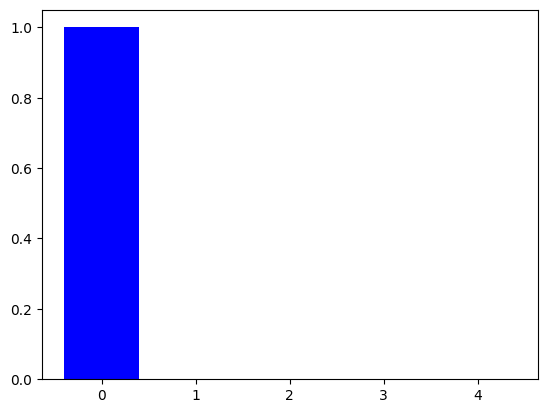

x = [1. 0. 0. 0. 0.]

---------------- Step i = 1 ----------------


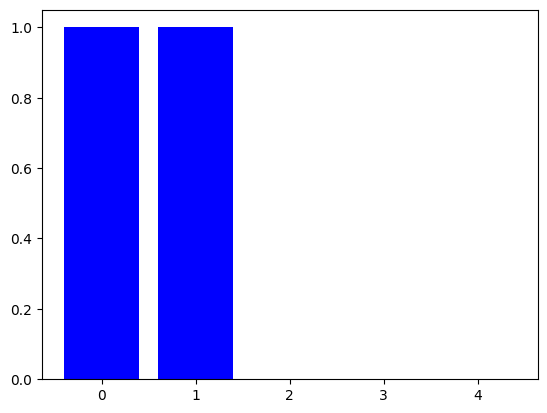

x = [1. 1. 0. 0. 0.]

---------------- Step i = 2 ----------------


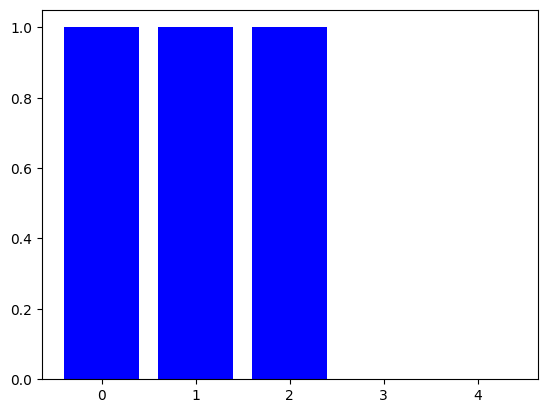

x = [1. 1. 1. 0. 0.]

---------------- Step i = 3 ----------------


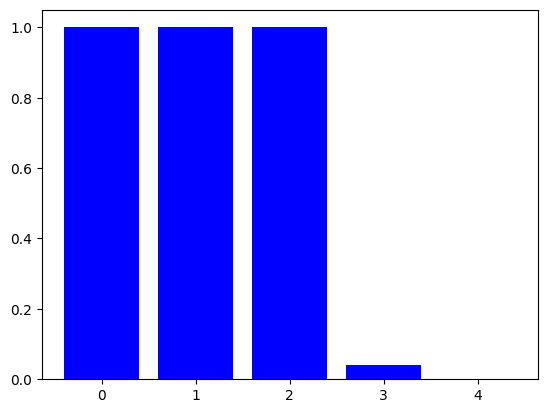

x = [1.         1.         1.         0.04171151 0.        ]

---------------- Step i = 4 ----------------


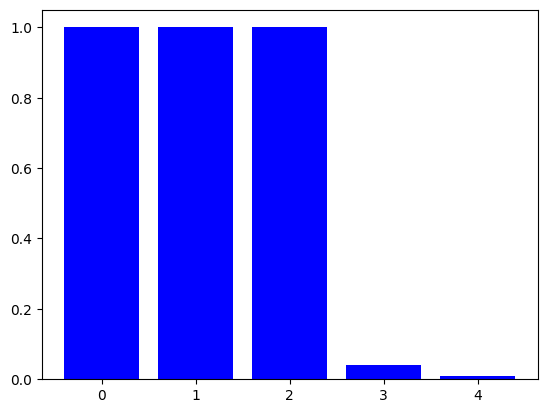

x = [1.         1.         1.         0.04171151 0.00865398]


array([1.        , 1.        , 1.        , 0.04171151, 0.00865398])

In [ ]:
# -*- coding: utf-8 -*-
"""
Created on Thu Jul 26 14:11:15 2018

@author: lsalaun

© 2020 Nokia
Licensed under Creative Commons Attribution Non Commercial 4.0 International
SPDX-License-Identifier: CC-BY-NC-4.0

"""

import numpy as np


K = 5 # Number of users
L = 1 # Number of subcarriers
# Radius of the cell
Radius = 1000
# Min distance between user and BS = 35 m
rmin = 35

#np.random.seed(1)
G = generateGains(K,L,Radius,rmin)

# B : total bandwidth = 5 MHz
B = 5*10**6
W = np.ones(L)*B/L

# Noise value per Hertz = -174 dBm/Hz
Noise_Hz = 10**((-174-30)/10)
N = np.ones(K*L)*Noise_Hz*B/L
N_G = computeN_G(G,N)

# Decoding order
pi,pi_inv = computePi(G,N)

# Random weights
w = np.random.rand(K)

# Considered subcarrier and active users
lsub = 0
ksub = np.arange(K)

# Power budget
Pmax = 1

print('pi =',pi)
print('w =',w)

print('\n----------------------- TEST SCPC on a single subcarrier with 5 users -----------------------')
SCPC_barplot(K,Pmax,N_G[lsub],lsub,ksub,pi,pi_inv,w,W)

## Generate SCUS

pi = [[4 1 3 0 2]]
w = [0.29828233 0.56996491 0.59087276 0.57432525 0.65320082]
G =
 [[4.20993471e-12]
 [4.93942037e-13]
 [4.99432852e-12]
 [1.58377777e-12]
 [2.94755871e-13]]

----------------------- TEST SCUS and i-SCUS on a single subcarrier with at most 3 active users out of 5  -----------------------


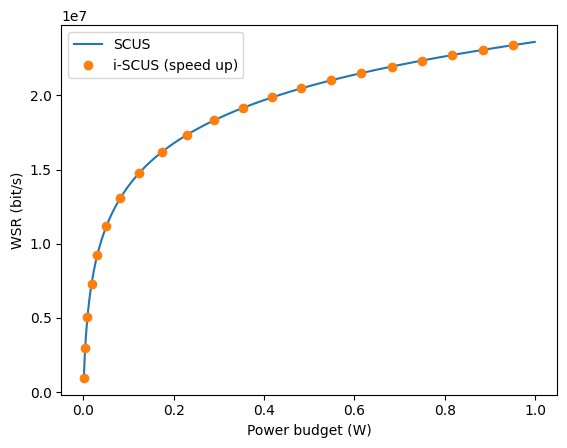

In [ ]:
# -*- coding: utf-8 -*-
"""
Created on Thu Jul 26 14:11:15 2018

@author: lsalaun

© 2020 Nokia
Licensed under Creative Commons Attribution Non Commercial 4.0 International
SPDX-License-Identifier: CC-BY-NC-4.0

"""

import numpy as np
import matplotlib.pyplot as plt


K = 5 # Number of users
L = 1 # Number of subcarriers
Multiplex = 3 # Number of users per subcarrier
# Radius of the cell
Radius = 1000
# Min distance between user and BS = 35 m
rmin = 35

#np.random.seed(1)
G = generateGains(K,L,Radius,rmin)

# B : total bandwidth = 5 MHz
B = 5*10**6
W = np.ones(L)*B/L

# Noise value per Hertz = -174 dBm/Hz
Noise_Hz = 10**((-174-30)/10)
N = np.ones(K*L)*Noise_Hz*B/L
N_G = computeN_G(G,N)

# Decoding order
pi,pi_inv = computePi(G,N)

# Random weights
w = np.random.rand(K)

# Considered subcarrier
lsub = 0

# Power budget
Pmax = 1

print('pi =',pi)
print('w =',w)
print('G =\n',G)

print('\n----------------------- TEST SCUS and i-SCUS on a single subcarrier with at most 3 active users out of 5  -----------------------')
espilon = 1e-3
X = np.arange(espilon,Pmax,espilon)
Y_SCUS = np.zeros(X.shape)
Y_SpeedUp_SCUS = np.zeros(X.shape)

# speedUp_SCUS initialization
speedUp_SCUS = SpeedUpSCUS(K,Multiplex,Pmax,N_G[lsub],lsub,pi,pi_inv,w,W)

for index in range(len(X)):
    # SCUS computation
    x_f2l = SCUS_first2last(K,Multiplex,X[index],N_G[lsub],lsub,pi,w,W)
    p_f2l = X2P_sc(x_f2l,pi,K,lsub)
    Y_SCUS[index] = np.sum(computeWSR_sc(K,lsub,N_G[lsub],pi,pi_inv,w,W,p_f2l))

    # speedUp_SCUS computation
    x,p,wsr = speedUp_SCUS.speedUp_SCUS(X[index])
    Y_SpeedUp_SCUS[index] = np.sum(wsr)

plt.figure(0)
plt.plot(X,Y_SCUS,'-',label='SCUS')
plt.plot(X,Y_SpeedUp_SCUS,'o',markevery=0.05,label='i-SCUS (speed up)')
plt.xlabel('Power budget (W)')
plt.ylabel('WSR (bit/s)')
plt.legend()
plt.show()

# PSO NOMA Solver

In [ ]:
# -*- coding: utf-8 -*-
import numpy as np

import time

# --- 1. Setup Parameter (Sesuai paper) ---
K = 5           # Jumlah pengguna
L = 10          # Jumlah subcarrier
Multiplex = 2   # Maks pengguna per subcarrier (NOMA)
Pmax = 1        # Total power budget
Radius = 1000   # Radius sel
rmin = 35       # Jarak minimum
np.random.seed(42) # Agar hasil bisa direproduksi

# Generate Gains dan Parameter Sistem
G = generateGains(K, L, Radius, rmin)
B = 5*10**6
W = np.ones(L) * B / L
Noise_Hz = 10**((-174-30)/10)
N = np.ones(K*L) * Noise_Hz * B / L
N_G = computeN_G(G, N)
pi, pi_inv = computePi(G, N)
w = np.random.rand(K) # Weighted factor untuk user fairness
PmaxN = Pmax * np.ones(L)

# --- 2. Implementasi PSO Solver ---
def pso_noma_solver(K, L, Multiplex, Pmax, N_G, pi, pi_inv, w, W, n_particles=20, n_iterations=30):
    pos = np.random.rand(n_particles, L)
    pos = pos * (Pmax / np.sum(pos, axis=1)[:, np.newaxis])
    vel = np.zeros((n_particles, L))
    pbest_pos = np.copy(pos)
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos = np.zeros(L)
    gbest_score = -np.inf

    # History tracking for PSO
    gbest_score_history = []
    gbest_pos_history = []

    # Pre-computation SCUS untuk mempercepat PSO
    suSCUS = [SpeedUpSCUS(K, Multiplex, Pmax, N_G[l], l, pi, pi_inv, w, W) for l in range(L)]

    for i in range(n_iterations):
        for p in range(n_particles):
            current_wsr = sum(suSCUS[l].speedUp_SCUS_onlyWSR(pos[p, l]) for l in range(L))
            if current_wsr > pbest_score[p]:
                pbest_score[p] = current_wsr
                pbest_pos[p] = np.copy(pos[p])
            if current_wsr > gbest_score:
                gbest_score = current_wsr
                gbest_pos = np.copy(pos[p])

        # Store history
        gbest_score_history.append(gbest_score)
        gbest_pos_history.append(gbest_pos)

        # Update PSO (Velocity & Position)
        r1, r2 = np.random.rand(), np.random.rand()
        vel = 0.5 * vel + 1.5 * r1 * (pbest_pos - pos) + 1.5 * r2 * (gbest_pos - pos)
        pos = np.clip(pos + vel, 1e-9, Pmax)
        pos = pos * (Pmax / np.sum(pos, axis=1)[:, np.newaxis]) # Constraint: Sum Power = Pmax

    return gbest_score, gbest_pos, gbest_score_history, gbest_pos_history

# --- 3. Evaluasi dan Perbandingan ---
results = {}

# A. Run OPT-JSPA (Solusi Optimal/Benchmark)
print("Running OPT-JSPA...")
start = time.time()
delta=0.01
p_opt, wsr_opt, _, _ = opt_JSPA(K, L, Multiplex, Pmax, PmaxN, N_G, pi, pi_inv, w, W, delta)
results['OPT-JSPA'] = {'wsr': np.sum(wsr_opt), 'time': time.time() - start}

# B. Run Grad-JSPA (Solusi Heuristik Paper)
print("Running Grad-JSPA...")
start = time.time()
p_grad, wsr_grad, _, _ = SpeedUp_Grad_JSPA(K, L, Multiplex, Pmax, N_G, pi, pi_inv, w, W, delta=0.001)
results['Grad-JSPA'] = {'wsr': np.sum(wsr_grad), 'time': time.time() - start}

# C. Run PSO Solver
print("Running PSO...")
start = time.time()
wsr_pso, p_pso, pso_wsr_history, pso_pos_history = pso_noma_solver(K, L, Multiplex, Pmax, N_G, pi, pi_inv, w, W)
results['PSO'] = {'wsr': wsr_pso, 'time': time.time() - start, 'wsr_history': pso_wsr_history, 'pos_history': pso_pos_history}

# --- 4. Tampilkan Tabel Hasil ---
print("\n" + "="*45)
print(f"{'Metode':<15} | {'WSR (bps)':<15} | {'Waktu (s)':<10}")
print("-" * 45)
for method, data in results.items():
    print(f"{method:<15} | {data['wsr']:<15.4e} | {data['time']:<10.4f}")
print("="*45)

# Display PSO History
print("\n--- PSO WSR History per Iteration ---")
for i, wsr in enumerate(pso_wsr_history):
    print(f"Iteration {i+1}: WSR = {wsr:.4e}")

Running OPT-JSPA...
Running Grad-JSPA...
Running PSO...

Metode          | WSR (bps)       | Waktu (s) 
---------------------------------------------
OPT-JSPA        | 1.6746e+08      | 0.0004    
Grad-JSPA       | 1.6746e+08      | 0.0003    
PSO             | 3.3484e+07      | 0.0122    

--- PSO WSR History per Iteration ---
Iteration 1: WSR = 3.3216e+07
Iteration 2: WSR = 3.3216e+07
Iteration 3: WSR = 3.3282e+07
Iteration 4: WSR = 3.3399e+07
Iteration 5: WSR = 3.3431e+07
Iteration 6: WSR = 3.3451e+07
Iteration 7: WSR = 3.3451e+07
Iteration 8: WSR = 3.3468e+07
Iteration 9: WSR = 3.3468e+07
Iteration 10: WSR = 3.3475e+07
Iteration 11: WSR = 3.3480e+07
Iteration 12: WSR = 3.3480e+07
Iteration 13: WSR = 3.3481e+07
Iteration 14: WSR = 3.3482e+07
Iteration 15: WSR = 3.3482e+07
Iteration 16: WSR = 3.3482e+07
Iteration 17: WSR = 3.3482e+07
Iteration 18: WSR = 3.3482e+07
Iteration 19: WSR = 3.3482e+07
Iteration 20: WSR = 3.3482e+07
Iteration 21: WSR = 3.3483e+07
Iteration 22: WSR = 3.3483e+

# GA NOMA Solver

In [ ]:
import numpy as np


def ga_noma_solver(K, L, Multiplex, Pmax, N_G, pi, pi_inv, w, W, pop_size=40, generations=50):
    """
    Genetic Algorithm Solver untuk optimasi daya NOMA JSPA.
    """
    # Pre-computation SCUS untuk mempercepat evaluasi fitness
    suSCUS = [SpeedUpSCUS(K, Multiplex, Pmax, N_G[l], l, pi, pi_inv, w, W) for l in range(L)]

    def fitness_func(individual):
        # Menghitung total WSR untuk satu individu kromosom
        return sum(suSCUS[l].speedUp_SCUS_onlyWSR(individual[l]) for l in range(L))

    # 1. Inisialisasi Populasi (Kromosom: alokasi daya per subcarrier)
    population = np.random.rand(pop_size, L)
    # Normalisasi agar total daya tiap individu = Pmax
    population = population * (Pmax / np.sum(population, axis=1)[:, np.newaxis])

    best_individual = None
    best_wsr = -np.inf
    best_wsr_history = [] # Added for history tracking
    best_individual_history = [] # Added for history tracking

    for gen in range(generations):
        # 2. Evaluasi Fitness
        scores = np.array([fitness_func(ind) for ind in population])

        # Simpan yang terbaik (Elitism)
        idx_best = np.argmax(scores)
        if scores[idx_best] > best_wsr:
            best_wsr = scores[idx_best]
            best_individual = np.copy(population[idx_best])

        # Store history for current generation
        best_wsr_history.append(best_wsr)
        best_individual_history.append(best_individual) # Store the current best individual

        # 3. Seleksi (Roulette Wheel / Tournament)
        # Gunakan rank-based selection sederhana
        probs = scores / (np.sum(scores) + 1e-9)
        indices = np.random.choice(range(pop_size), size=pop_size, p=probs)
        population = population[indices]

        # 4. Crossover (Arithmetic Crossover)
        for i in range(0, pop_size, 2):
            if np.random.rand() < 0.8: # Crossover rate
                alpha = np.random.rand()
                # Kombinasi linear antara dua orang tua
                parent1, parent2 = population[i].copy(), population[i+1].copy()
                population[i] = alpha * parent1 + (1 - alpha) * parent2
                population[i+1] = (1 - alpha) * parent1 + alpha * parent2

        # 5. Mutasi
        mutation_rate = 0.1
        for i in range(pop_size):
            if np.random.rand() < mutation_rate:
                gene_idx = np.random.randint(0, L)
                population[i, gene_idx] = np.random.rand() * Pmax

        # 6. Perbaikan (Repair) Constraint: Sum Power = Pmax
        population = np.maximum(1e-9, population) # Hindari nol
        population = population * (Pmax / np.sum(population, axis=1)[:, np.newaxis])

    return best_wsr, best_individual, best_wsr_history, best_individual_history

Running Genetic Algorithm (GA)...

Metode               | WSR (bps)       | Waktu (s) 
-------------------------------------------------------
OPT-JSPA             | 1.6746e+08      | 0.0004    
Grad-JSPA            | 1.6746e+08      | 0.0003    
PSO                  | 3.3484e+07      | 0.0122    
Genetic Algorithm    | 3.3378e+07      | 0.0481    

--- GA WSR History per Generation ---
Generation 1: WSR = 3.3113e+07
Generation 2: WSR = 3.3201e+07
Generation 3: WSR = 3.3304e+07
Generation 4: WSR = 3.3377e+07
Generation 5: WSR = 3.3378e+07
Generation 6: WSR = 3.3378e+07
Generation 7: WSR = 3.3378e+07
Generation 8: WSR = 3.3378e+07
Generation 9: WSR = 3.3378e+07
Generation 10: WSR = 3.3378e+07
Generation 11: WSR = 3.3378e+07
Generation 12: WSR = 3.3378e+07
Generation 13: WSR = 3.3378e+07
Generation 14: WSR = 3.3378e+07
Generation 15: WSR = 3.3378e+07
Generation 16: WSR = 3.3378e+07
Generation 17: WSR = 3.3378e+07
Generation 18: WSR = 3.3378e+07
Generation 19: WSR = 3.3378e+07
Generation 

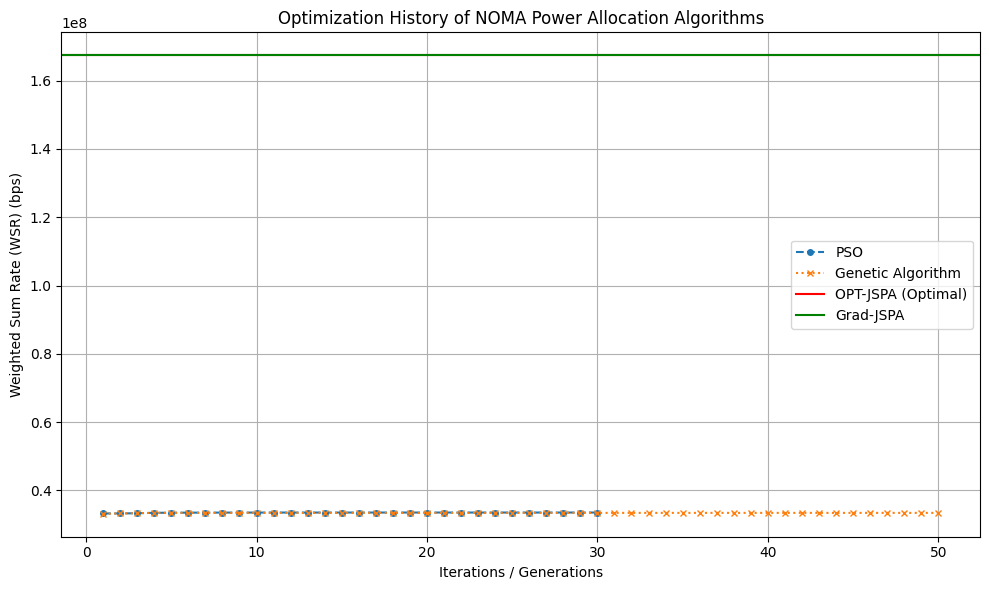

In [ ]:
# --- Tambahkan ini ke bagian evaluasi di skrip sebelumnya ---

print("Running Genetic Algorithm (GA)...")
start = time.time()
wsr_ga, p_ga, ga_wsr_history, ga_pos_history = ga_noma_solver(K, L, Multiplex, Pmax, N_G, pi, pi_inv, w, W)
results['Genetic Algorithm'] = {'wsr': wsr_ga, 'time': time.time() - start, 'wsr_history': ga_wsr_history, 'pos_history': ga_pos_history}

# Tampilkan Hasil Akhir
print("\n" + "="*55)
print(f"{'Metode':<20} | {'WSR (bps)':<15} | {'Waktu (s)':<10}")
print("-" * 55)
for method, data in results.items():
    print(f"{method:<20} | {data['wsr']:<15.4e} | {data['time']:<10.4f}")
print("="*55)

# Display GA History
print("\n--- GA WSR History per Generation ---")
for i, wsr in enumerate(ga_wsr_history):
    print(f"Generation {i+1}: WSR = {wsr:.4e}")


# --- Plotting Optimization History ---
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot PSO History
plt.plot(range(1, len(results['PSO']['wsr_history']) + 1),
         results['PSO']['wsr_history'], label='PSO',
         marker='o', markersize=4, linestyle='--')

# Plot GA History
plt.plot(range(1, len(results['Genetic Algorithm']['wsr_history']) + 1),
         results['Genetic Algorithm']['wsr_history'], label='Genetic Algorithm',
         marker='x', markersize=4, linestyle=':')

# Plot TLBO History (if available)
if 'TLBO' in results and 'wsr_history' in results['TLBO']:
    plt.plot(range(1, len(results['TLBO']['wsr_history']) + 1),
             results['TLBO']['wsr_history'], label='TLBO',
             marker='s', markersize=4, linestyle='-.')

# Plot OPT-JSPA and Grad-JSPA as horizontal lines
plt.axhline(y=results['OPT-JSPA']['wsr'], color='r', linestyle='-', label='OPT-JSPA (Optimal)')
plt.axhline(y=results['Grad-JSPA']['wsr'], color='g', linestyle='-', label='Grad-JSPA')

plt.title('Optimization History of NOMA Power Allocation Algorithms')
plt.xlabel('Iterations / Generations')
plt.ylabel('Weighted Sum Rate (WSR) (bps)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# TLBO NOMA Solver

In [ ]:
import numpy as np

import time

def tlbo_noma_solver(K, L, Multiplex, Pmax, N_G, pi, pi_inv, w, W, n_students=20, n_iter=50):
    """
    TLBO Solver untuk JSPA NOMA.
    Siswa (Student) = Vektor alokasi daya [p1, p2, ..., pL]
    Fitness = Total Weighted Sum-Rate
    """
    # Pre-computation untuk efisiensi
    suSCUS = [SpeedUpSCUS(K, Multiplex, Pmax, N_G[l], l, pi, pi_inv, w, W) for l in range(L)]

    def get_fitness(individual):
        return sum(suSCUS[l].speedUp_SCUS_onlyWSR(individual[l]) for l in range(L))

    # Inisialisasi Populasi (Siswa)
    students = np.random.rand(n_students, L)
    students = students * (Pmax / np.sum(students, axis=1)[:, np.newaxis])

    history = []

    for gen in range(n_iter):
        # --- A. TEACHER PHASE ---
        # Siswa terbaik menjadi Guru
        fitness_scores = np.array([get_fitness(s) for s in students])
        best_idx = np.argmax(fitness_scores)
        teacher = students[best_idx]
        mean_result = np.mean(students, axis=0)

        for i in range(n_students):
            # Faktor mengajar (TF) bisa 1 atau 2 secara acak
            tf = np.random.randint(1, 3)
            diff_mean = np.random.rand(L) * (teacher - tf * mean_result)

            new_student = np.clip(students[i] + diff_mean, 1e-9, Pmax)
            new_student *= (Pmax / np.sum(new_student)) # Constraint repair

            if get_fitness(new_student) > fitness_scores[i]:
                students[i] = new_student
                fitness_scores[i] = get_fitness(new_student)

        # --- B. LEARNER PHASE ---
        for i in range(n_students):
            # Pilih teman belajar secara acak
            partner_idx = np.random.choice([idx for idx in range(n_students) if idx != i])

            if fitness_scores[i] < fitness_scores[partner_idx]:
                new_student = students[i] + np.random.rand(L) * (students[partner_idx] - students[i])
            else:
                new_student = students[i] + np.random.rand(L) * (students[i] - students[partner_idx])

            new_student = np.clip(new_student, 1e-9, Pmax)
            new_student *= (Pmax / np.sum(new_student)) # Constraint repair

            if get_fitness(new_student) > fitness_scores[i]:
                students[i] = new_student
                fitness_scores[i] = get_fitness(new_student)

        history.append(np.max(fitness_scores))

    return np.max(fitness_scores), students[np.argmax(fitness_scores)], history

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

# --- EKSEKUSI DAN PERBANDINGAN ---
print("Memulai evaluasi perbandingan...")

# A. Metode Paper
t0 = time.time()
delta=0.01
p_opt, wsr_opt, _, _ = opt_JSPA(K, L, Multiplex, Pmax, PmaxN, N_G, pi, pi_inv, w, W, delta)
time_opt = time.time() - t0
results['OPT-JSPA'] = {'wsr': np.sum(wsr_opt), 'time': time_opt}

t0 = time.time()
delta=0.001
p_grad, wsr_grad, _, _ = SpeedUp_Grad_JSPA(K, L, Multiplex, Pmax, N_G, pi, pi_inv, w, W, delta)
time_grad = time.time() - t0
results['Grad-JSPA'] = {'wsr': np.sum(wsr_grad), 'time': time_grad}

# B. Metaheuristik
# PSO is already defined and run in cell 'mA4mgfcJ88bM'
# GA is already defined and run in cell 'mhHxUGqw-Swo'

# TLBO Solver
print("Running TLBO...")
t0 = time.time()
wsr_tlbo, p_tlbo, tlbo_wsr_history = tlbo_noma_solver(K, L, Multiplex, Pmax, N_G, pi, pi_inv, w, W)
time_tlbo = time.time() - t0
results['TLBO'] = {'wsr': wsr_tlbo, 'time': time_tlbo, 'wsr_history': tlbo_wsr_history, 'pos_history': p_tlbo} # p_tlbo here is the best individual, not history


# --- OUTPUT TABEL ---
print("\n" + "="*60)
print(f"{'Metode':<20} | {'WSR (bps)':<15} | {'Waktu (s)':<10}")
print("-" * 60)
for method, data in results.items():
    print(f"{method:<20} | {data['wsr']:<15.4e} | {data['time']:<10.4f}")
print("="*60)

# Display TLBO History
print("\n--- TLBO WSR History per Iteration ---")
for i, wsr in enumerate(tlbo_wsr_history):
    print(f"Iteration {i+1}: WSR = {wsr:.4e}")


Memulai evaluasi perbandingan...
Running TLBO...

Metode               | WSR (bps)       | Waktu (s) 
------------------------------------------------------------
OPT-JSPA             | 1.6746e+08      | 0.0006    
Grad-JSPA            | 1.6746e+08      | 0.0003    
PSO                  | 3.3484e+07      | 0.0122    
Genetic Algorithm    | 3.3378e+07      | 0.0481    
TLBO                 | 3.3492e+07      | 0.1626    

--- TLBO WSR History per Iteration ---
Iteration 1: WSR = 3.3296e+07
Iteration 2: WSR = 3.3296e+07
Iteration 3: WSR = 3.3381e+07
Iteration 4: WSR = 3.3448e+07
Iteration 5: WSR = 3.3448e+07
Iteration 6: WSR = 3.3457e+07
Iteration 7: WSR = 3.3469e+07
Iteration 8: WSR = 3.3478e+07
Iteration 9: WSR = 3.3478e+07
Iteration 10: WSR = 3.3478e+07
Iteration 11: WSR = 3.3483e+07
Iteration 12: WSR = 3.3486e+07
Iteration 13: WSR = 3.3487e+07
Iteration 14: WSR = 3.3488e+07
Iteration 15: WSR = 3.3489e+07
Iteration 16: WSR = 3.3489e+07
Iteration 17: WSR = 3.3489e+07
Iteration 18: WSR =

Running Tawuran Strategy Optimization (TSO)...

Metode               | WSR (bps)       | Waktu (s) 
------------------------------------------------------------
OPT-JSPA             | 1.6746e+08      | 0.0006    
Grad-JSPA            | 1.6746e+08      | 0.0003    
PSO                  | 3.3484e+07      | 0.0122    
Genetic Algorithm    | 3.3378e+07      | 0.0481    
TLBO                 | 3.3492e+07      | 0.1626    
TSO                  | 3.3491e+07      | 0.3330    

--- TSO WSR History per Iteration ---
Iteration 1: WSR = 3.3072e+07
Iteration 2: WSR = 3.3222e+07
Iteration 3: WSR = 3.3411e+07
Iteration 4: WSR = 3.3424e+07
Iteration 5: WSR = 3.3457e+07
Iteration 6: WSR = 3.3469e+07
Iteration 7: WSR = 3.3471e+07
Iteration 8: WSR = 3.3471e+07
Iteration 9: WSR = 3.3471e+07
Iteration 10: WSR = 3.3476e+07
Iteration 11: WSR = 3.3476e+07
Iteration 12: WSR = 3.3481e+07
Iteration 13: WSR = 3.3483e+07
Iteration 14: WSR = 3.3484e+07
Iteration 15: WSR = 3.3486e+07
Iteration 16: WSR = 3.3486e+07
I

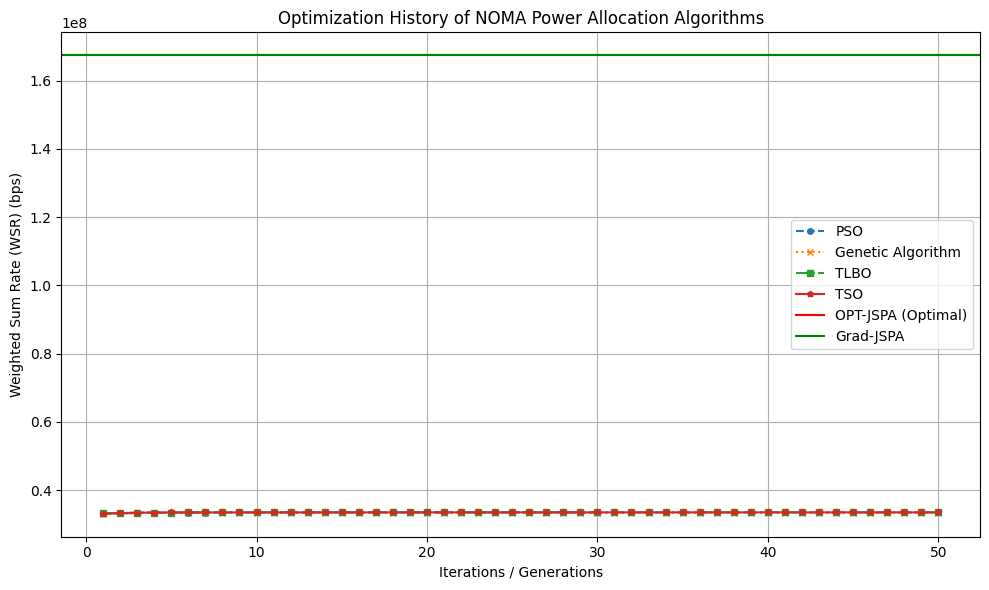

In [ ]:
import numpy as np
import time

def tso_noma_solver(K, L, Multiplex, Pmax, N_G, pi, pi_inv, w, W, swarm_size=40, num_gangs=4, iterations=50):
    """
    Tawuran Strategy Optimization (TSO) Solver for NOMA JSPA.
    """

    # Pre-computation SCUS for fitness evaluation efficiency
    suSCUS = [SpeedUpSCUS(K, Multiplex, Pmax, N_G[l], l, pi, pi_inv, w, W) for l in range(L)]

    def get_fitness(individual):
        # Ensure individual is clipped and normalized before WSR calculation
        ind_clipped = np.clip(individual, 1e-9, Pmax) # Ensure non-negative and within Pmax
        ind_normalized = ind_clipped * (Pmax / np.sum(ind_clipped)) # Ensure sum == Pmax
        return sum(suSCUS[l].speedUp_SCUS_onlyWSR(ind_normalized[l]) for l in range(L))

    # 1. Initialization
    # Generate 'Total Students' randomly in the search space (Power allocation vectors)
    students = np.random.rand(swarm_size, L)
    students = students * (Pmax / np.sum(students, axis=1)[:, np.newaxis]) # Normalize

    # Divide students into 'num_gangs' based on initial proximity (random assignment for simplicity)
    gang_assignments = np.random.randint(0, num_gangs, swarm_size)

    # Set internal parameters
    solidarity_factor = 0.5 # sf
    aggression_level = 0.1  # al
    merging_factor = 0.1    # for collective personality merging
    expulsion_threshold_ratio = 0.7 # Students with fitness below mean * ratio get expelled
    gaussian_noise_std_dev = 0.01 * Pmax # Standard deviation for Gaussian noise in brawl

    best_global_wsr = -np.inf
    best_global_pos = None
    tso_wsr_history = []

    for gen in range(iterations):
        # 2. Evaluation
        fitness_scores = np.array([get_fitness(s) for s in students])

        # Update global best
        current_best_idx = np.argmax(fitness_scores)
        if fitness_scores[current_best_idx] > best_global_wsr:
            best_global_wsr = fitness_scores[current_best_idx]
            best_global_pos = np.copy(students[current_best_idx])
        tso_wsr_history.append(best_global_wsr)

        # Prepare gang data
        gang_members = [[] for _ in range(num_gangs)]
        for i, gang_id in enumerate(gang_assignments):
            gang_members[gang_id].append(i)

        gang_leaders_pos = [None] * num_gangs
        gang_leaders_fitness = [-np.inf] * num_gangs
        gang_centroids = [None] * num_gangs
        gang_mean_fitness = [0.0] * num_gangs

        for g_id in range(num_gangs):
            if not gang_members[g_id]: # Skip empty gangs
                continue

            gang_student_indices = gang_members[g_id]
            gang_student_positions = students[gang_student_indices]
            gang_student_fitness = fitness_scores[gang_student_indices]

            # Identify 'Leader'
            leader_in_gang_idx = np.argmax(gang_student_fitness)
            gang_leaders_pos[g_id] = gang_student_positions[leader_in_gang_idx]
            gang_leaders_fitness[g_id] = gang_student_fitness[leader_in_gang_idx]

            # Calculate 'Collective Personality' (Mean position and mean fitness)
            gang_centroids[g_id] = np.mean(gang_student_positions, axis=0)
            gang_mean_fitness[g_id] = np.mean(gang_student_fitness)

        # 3. Optimization Loop (Generations)
        # PHASE A: INTERNAL SOLIDARITY (Nongkrong/Hangout)
        for g_id in range(num_gangs):
            if gang_leaders_pos[g_id] is None: # Skip if no leader (empty gang)
                continue
            leader_pos = gang_leaders_pos[g_id]
            for s_idx in gang_members[g_id]:
                r = np.random.rand(L)
                new_student_pos = students[s_idx] + r * solidarity_factor * (leader_pos - students[s_idx])
                # Constraint Repair (repeated here for immediate effect and within loop logic)
                new_student_pos = np.clip(new_student_pos, 1e-9, Pmax)
                new_student_pos = new_student_pos * (Pmax / np.sum(new_student_pos))
                if get_fitness(new_student_pos) > fitness_scores[s_idx]:
                    students[s_idx] = new_student_pos
                    fitness_scores[s_idx] = get_fitness(new_student_pos)

        # PHASE B: COLLECTIVE PERSONALITY MERGING
        for g_id in range(num_gangs):
            if gang_centroids[g_id] is None: # Skip if no centroid (empty gang)
                continue
            centroid = gang_centroids[g_id]
            for s_idx in gang_members[g_id]:
                students[s_idx] = students[s_idx] + merging_factor * (centroid - students[s_idx])
                # Constraint Repair
                students[s_idx] = np.clip(students[s_idx], 1e-9, Pmax)
                students[s_idx] = students[s_idx] * (Pmax / np.sum(students[s_idx]))
                fitness_scores[s_idx] = get_fitness(students[s_idx]) # Recalculate fitness after move

        # PHASE C: THE BRAWL (Inter-group Conflict)
        if num_gangs >= 2:
            gang_ids_to_brawl = np.random.choice(num_gangs, 2, replace=False)
            g_a_id, g_b_id = gang_ids_to_brawl[0], gang_ids_to_brawl[1]

            # Ensure gangs are not empty before proceeding
            if gang_members[g_a_id] and gang_members[g_b_id]:
                mean_fitness_A = gang_mean_fitness[g_a_id]
                mean_fitness_B = gang_mean_fitness[g_b_id]
                leader_g_b_pos = gang_leaders_pos[g_b_id]

                if mean_fitness_A < mean_fitness_B: # Gang A attacks
                    for s_idx in gang_members[g_a_id]:
                        new_student_pos = students[s_idx] + aggression_level * (leader_g_b_pos - students[s_idx])
                        # Constraint Repair
                        new_student_pos = np.clip(new_student_pos, 1e-9, Pmax)
                        new_student_pos = new_student_pos * (Pmax / np.sum(new_student_pos))
                        students[s_idx] = new_student_pos
                        fitness_scores[s_idx] = get_fitness(students[s_idx])
                else: # Gang A takes defensive stance or provocative behavior (add noise)
                    for s_idx in gang_members[g_a_id]:
                        noise = np.random.normal(0, gaussian_noise_std_dev, L)
                        new_student_pos = students[s_idx] + noise
                        # Constraint Repair
                        new_student_pos = np.clip(new_student_pos, 1e-9, Pmax)
                        new_student_pos = new_student_pos * (Pmax / np.sum(new_student_pos))
                        students[s_idx] = new_student_pos
                        fitness_scores[s_idx] = get_fitness(students[s_idx])

        # PHASE D: DISPERSION & RECRUITMENT
        mean_current_fitness = np.mean(fitness_scores)
        low_fitness_threshold = mean_current_fitness * expulsion_threshold_ratio

        for s_idx in range(swarm_size):
            if fitness_scores[s_idx] < low_fitness_threshold:
                # Perform "Expulsion" (Reset position randomly)
                new_pos = np.random.rand(L)
                new_pos = new_pos * (Pmax / np.sum(new_pos)) # Constraint Repair
                students[s_idx] = new_pos
                fitness_scores[s_idx] = get_fitness(students[s_idx])
                # Reassign to a random gang (new recruit)
                gang_assignments[s_idx] = np.random.randint(0, num_gangs)

        # PHASE E: CONSTRAINT REPAIR (Final check and normalization)
        students = np.maximum(1e-9, students) # Ensure no zero or negative power
        students = students * (Pmax / np.sum(students, axis=1)[:, np.newaxis])

    # 4. Return Global Best Solution
    final_fitness_scores = np.array([get_fitness(s) for s in students]) # Re-evaluate after last phase
    global_best_idx = np.argmax(final_fitness_scores)
    if final_fitness_scores[global_best_idx] > best_global_wsr:
        best_global_wsr = final_fitness_scores[global_best_idx]
        best_global_pos = np.copy(students[global_best_idx])

    return best_global_wsr, best_global_pos, tso_wsr_history

# --- Add this to the evaluation section ---
print("Running Tawuran Strategy Optimization (TSO)...")
start = time.time()
wsr_tso, p_tso, tso_wsr_history = tso_noma_solver(K, L, Multiplex, Pmax, N_G, pi, pi_inv, w, W)
results['TSO'] = {'wsr': wsr_tso, 'time': time.time() - start, 'wsr_history': tso_wsr_history, 'pos_history': p_tso}

# Update and display the final comparison table
print("\n" + "="*60)
print(f"{'Metode':<20} | {'WSR (bps)':<15} | {'Waktu (s)':<10}")
print("-" * 60)
for method, data in results.items():
    print(f"{method:<20} | {data['wsr']:<15.4e} | {data['time']:<10.4f}")
print("="*60)

# Display TSO History
print("\n--- TSO WSR History per Iteration ---")
for i, wsr in enumerate(tso_wsr_history):
    print(f"Iteration {i+1}: WSR = {wsr:.4e}")

# --- Plotting Optimization History (updated to include TSO) ---
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot PSO History
plt.plot(range(1, len(results['PSO']['wsr_history']) + 1),
         results['PSO']['wsr_history'], label='PSO',
         marker='o', markersize=4, linestyle='--')

# Plot GA History
plt.plot(range(1, len(results['Genetic Algorithm']['wsr_history']) + 1),
         results['Genetic Algorithm']['wsr_history'], label='Genetic Algorithm',
         marker='x', markersize=4, linestyle=':')

# Plot TLBO History
if 'TLBO' in results and 'wsr_history' in results['TLBO']:
    plt.plot(range(1, len(results['TLBO']['wsr_history']) + 1),
             results['TLBO']['wsr_history'], label='TLBO',
             marker='s', markersize=4, linestyle='-.')

# Plot TSO History
plt.plot(range(1, len(results['TSO']['wsr_history']) + 1),
         results['TSO']['wsr_history'], label='TSO',
         marker='p', markersize=4, linestyle='-')

# Plot OPT-JSPA and Grad-JSPA as horizontal lines
plt.axhline(y=results['OPT-JSPA']['wsr'], color='r', linestyle='-', label='OPT-JSPA (Optimal)')
plt.axhline(y=results['Grad-JSPA']['wsr'], color='g', linestyle='-', label='Grad-JSPA')

plt.title('Optimization History of NOMA Power Allocation Algorithms')
plt.xlabel('Iterations / Generations')
plt.ylabel('Weighted Sum Rate (WSR) (bps)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

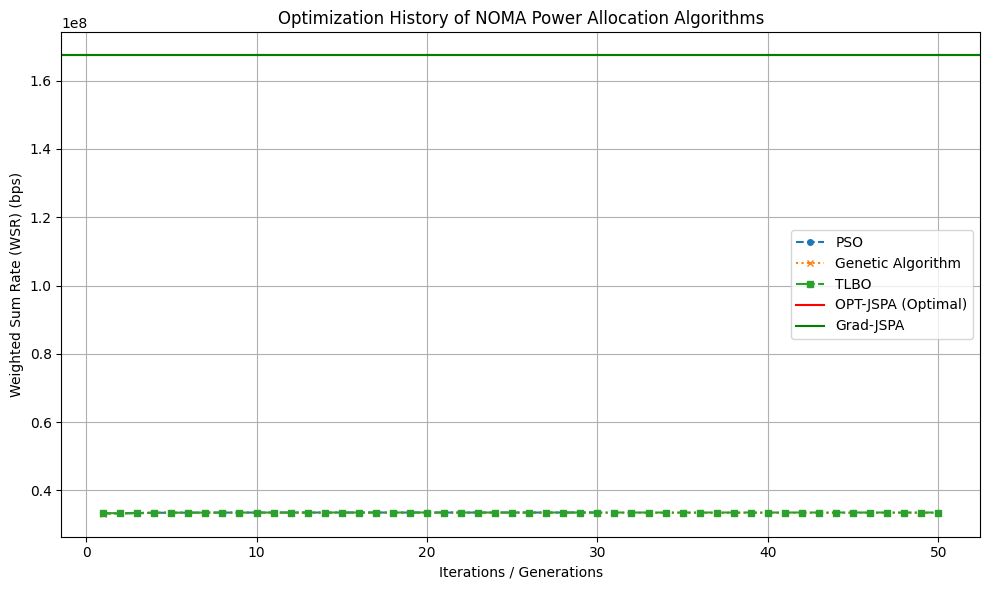

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot PSO History
plt.plot(range(1, len(results['PSO']['wsr_history']) + 1),
         results['PSO']['wsr_history'], label='PSO',
         marker='o', markersize=4, linestyle='--')

# Plot GA History
plt.plot(range(1, len(results['Genetic Algorithm']['wsr_history']) + 1),
         results['Genetic Algorithm']['wsr_history'], label='Genetic Algorithm',
         marker='x', markersize=4, linestyle=':')

# Plot TLBO History (if available)
if 'TLBO' in results and 'wsr_history' in results['TLBO']:
    plt.plot(range(1, len(results['TLBO']['wsr_history']) + 1),
             results['TLBO']['wsr_history'], label='TLBO',
             marker='s', markersize=4, linestyle='-.')

# Plot OPT-JSPA and Grad-JSPA as horizontal lines
plt.axhline(y=results['OPT-JSPA']['wsr'], color='r', linestyle='-', label='OPT-JSPA (Optimal)')
plt.axhline(y=results['Grad-JSPA']['wsr'], color='g', linestyle='-', label='Grad-JSPA')

plt.title('Optimization History of NOMA Power Allocation Algorithms')
plt.xlabel('Iterations / Generations')
plt.ylabel('Weighted Sum Rate (WSR) (bps)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# WAR TAKJIL Solver

In [ ]:
import numpy as np

def wto_noma_solver(K, L, Multiplex, Pmax, N_G, pi, pi_inv, w, W, n_particles=20, n_iterations=30, lambda_wto=0.5, r_antrean=None):
    """
    War Takjil Optimization (WTO) Solver untuk JSPA NOMA.
    Modifikasi dari PSO dengan menambahkan logika menghindari kerumunan/antrean.
    """
    # Pre-computation SCUS untuk mempercepat evaluasi fitness
    suSCUS = [SpeedUpSCUS(K, Multiplex, Pmax, N_G[l], l, pi, pi_inv, w, W) for l in range(L)]

    # Inisialisasi Partikel (Pembeli Takjil)
    pos = np.random.rand(n_particles, L)
    # Normalisasi agar total daya = Pmax
    pos = pos * (Pmax / np.sum(pos, axis=1)[:, np.newaxis])
    vel = np.zeros((n_particles, L))

    pbest_pos = np.copy(pos)
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos = np.zeros(L)
    gbest_score = -np.inf

    gbest_score_history = []

    # Jarak threshold dianggap "antrean ramai", default 20% dari Pmax
    if r_antrean is None:
        r_antrean = 0.2 * np.sqrt(L) * Pmax

    for i in range(n_iterations):
        # 1. Evaluasi Fitness & Update Pbest/Gbest
        for p in range(n_particles):
            current_wsr = sum(suSCUS[l].speedUp_SCUS_onlyWSR(pos[p, l]) for l in range(L))
            if current_wsr > pbest_score[p]:
                pbest_score[p] = current_wsr
                pbest_pos[p] = np.copy(pos[p])
            if current_wsr > gbest_score:
                gbest_score = current_wsr
                gbest_pos = np.copy(pos[p])

        gbest_score_history.append(gbest_score)

        # 2. Update Velocity & Position (LOGIKA WAR TAKJIL)
        for p in range(n_particles):
            # --- MENGHITUNG REPULSI KERUMUNAN ---
            repulsion = np.zeros(L)
            for q in range(n_particles):
                if p != q:
                    # Hitung jarak antar pembeli takjil (partikel)
                    dist = np.linalg.norm(pos[p] - pos[q])
                    # Jika berdekatan (sama-sama ngantri di stand yang sama)
                    if dist < r_antrean:
                        # Dorongan menjauhi (menghindari antrean)
                        repulsion += (pos[p] - pos[q])

            # --- UPDATE VELOCITY ---
            r1, r2 = np.random.rand(), np.random.rand()
            # PSO biasa + Dorongan menghindari antrean (War Takjil)
            # Perhatikan: repulsion DITAMBAH karena vektor (pos[p] - pos[q]) sudah menunjuk arah menjauhi
            vel[p] = (0.5 * vel[p]
                      + 1.5 * r1 * (pbest_pos[p] - pos[p])
                      + 1.5 * r2 * (gbest_pos - pos[p])
                      + lambda_wto * repulsion) # Ini soulmate-nya War Takjil!

            # --- UPDATE POSITION ---
            pos[p] = pos[p] + vel[p]

        # 3. Constraint Repair: Pastikan daya tidak negatif dan total = Pmax
        pos = np.clip(pos, 1e-9, Pmax)
        pos = pos * (Pmax / np.sum(pos, axis=1)[:, np.newaxis])

    return gbest_score, gbest_pos, gbest_score_history

# Compare All WSR

Calculating WSR for different Pmax values...
Pmax: 0.10 completed.
Pmax: 0.15 completed.
Pmax: 0.20 completed.
Pmax: 0.25 completed.
Pmax: 0.30 completed.
Pmax: 0.35 completed.
Pmax: 0.40 completed.
Pmax: 0.45 completed.
Pmax: 0.50 completed.
Pmax: 0.55 completed.
Pmax: 0.60 completed.
Pmax: 0.65 completed.
Pmax: 0.70 completed.
Pmax: 0.75 completed.
Pmax: 0.80 completed.
Pmax: 0.85 completed.
Pmax: 0.90 completed.
Pmax: 0.95 completed.
Pmax: 1.00 completed.

Metode          | Avg Waktu (s)   | Max Waktu (s)   | Min Waktu (s)  
------------------------------------------------------------
Grad-JSPA       | 0.0001          | 0.0002          | 0.0001         
PSO             | 0.0019          | 0.0025          | 0.0017         
GA              | 0.0051          | 0.0071          | 0.0046         
TLBO            | 0.0132          | 0.0248          | 0.0114         
War Takjil      | 0.0086          | 0.0176          | 0.0067         


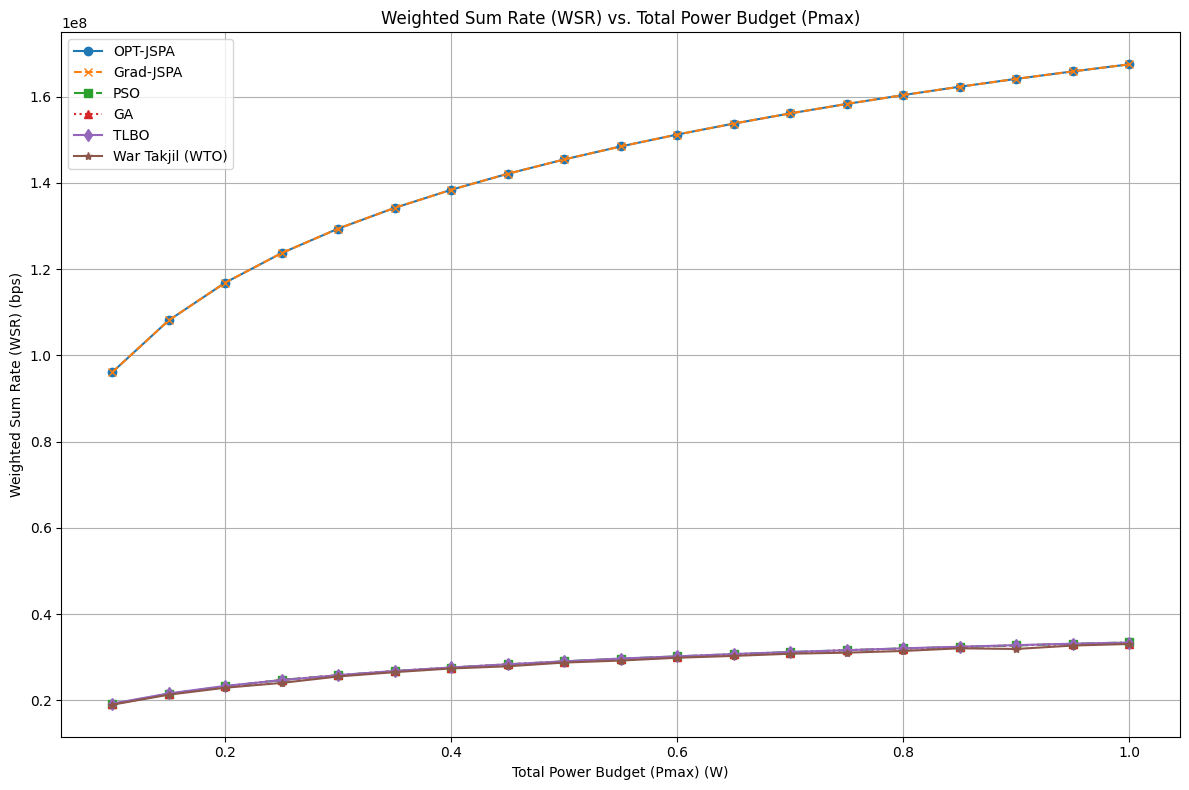

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

# --- 1. Setup Parameter (Sesuai paper) - Copied from cell 'mA4mgfcJ88bM' ---
K = 5           # Jumlah pengguna
L = 10          # Jumlah subcarrier
Multiplex = 2   # Maks pengguna per subcarrier (NOMA)
Pmax = 1        # Total power budget (This will be overridden by current_pmax in the loop)
Radius = 1000   # Radius sel
rmin = 35       # Jarak minimum
np.random.seed(42) # Agar hasil bisa direproduksi

# Generate Gains dan Parameter Sistem - Copied from cell 'mA4mgfcJ88bM'
G = generateGains(K, L, Radius, rmin)
B = 5*10**6
W = np.ones(L) * B / L
Noise_Hz = 10**((-174-30)/10)
N = np.ones(K*L) * Noise_Hz * B / L
N_G = computeN_G(G, N)
pi, pi_inv = computePi(G, N)
w = np.random.rand(K) # Weighted factor untuk user fairness
PmaxN = Pmax * np.ones(L) # This PmaxN will be updated in the loop


pmax_values = np.arange(0.1, 1.01, 0.05)
wsr_per_pmax_opt = []
wsr_per_pmax_grad = []
wsr_per_pmax_pso = []
wsr_per_pmax_ga = []
wsr_per_pmax_tlbo = []
wsr_per_pmax_wto = [] # Tambahkan untuk War Takjil

# Array untuk menyimpan waktu komputasi (untuk Tabel I di tugas)
time_per_pmax_opt = []
time_per_pmax_grad = []
time_per_pmax_pso = []
time_per_pmax_ga = []
time_per_pmax_tlbo = []
time_per_pmax_wto = []

print("Calculating WSR for different Pmax values...")
for current_pmax in pmax_values:
    # Update PmaxN based on the current_pmax
    current_pmax_n = current_pmax * np.ones(L)

    # Run opt_JSPA
    start = time.time()
    _, wsr_result_opt, _, _ = opt_JSPA(K, L, Multiplex, current_pmax, current_pmax_n, N_G, pi, pi_inv, w, W, discrete_step=0.01)
    wsr_per_pmax_opt.append(np.sum(wsr_result_opt))
    time_per_pmax_opt.append(time.time() - start)

    # Run Grad_JSPA
    start = time.time()
    _, wsr_result_grad, _, _ = SpeedUp_Grad_JSPA(K, L, Multiplex, current_pmax, N_G, pi, pi_inv, w, W, delta=0.001, rounding_step=None)
    wsr_per_pmax_grad.append(np.sum(wsr_result_grad))
    time_per_pmax_grad.append(time.time() - start)

    # Run PSO
    start = time.time()
    wsr_result_pso, _, _, _ = pso_noma_solver(K, L, Multiplex, current_pmax, N_G, pi, pi_inv, w, W, n_particles=10, n_iterations=10)
    wsr_per_pmax_pso.append(wsr_result_pso)
    time_per_pmax_pso.append(time.time() - start)

    # Run GA
    start = time.time()
    wsr_result_ga, _, _, _ = ga_noma_solver(K, L, Multiplex, current_pmax, N_G, pi, pi_inv, w, W, pop_size=20, generations=10)
    wsr_per_pmax_ga.append(wsr_result_ga)
    time_per_pmax_ga.append(time.time() - start)

    # Run TLBO
    start = time.time()
    wsr_result_tlbo, _, _ = tlbo_noma_solver(K, L, Multiplex, current_pmax, N_G, pi, pi_inv, w, W, n_students=10, n_iter=10)
    wsr_per_pmax_tlbo.append(wsr_result_tlbo)
    time_per_pmax_tlbo.append(time.time() - start)

    # Run WTO (War Takjil Optimization)
    start = time.time()
    wsr_result_wto, _, _ = wto_noma_solver(K, L, Multiplex, current_pmax, N_G, pi, pi_inv, w, W, n_particles=10, n_iterations=10, lambda_wto=0.8)
    wsr_per_pmax_wto.append(wsr_result_wto)
    time_per_pmax_wto.append(time.time() - start)

    print(f"Pmax: {current_pmax:.2f} completed.")

# Print Tabel Waktu Rata-rata (Membantu menjawab Tabel I di tugas)
print("\n" + "="*60)
print(f"{'Metode':<15} | {'Avg Waktu (s)':<15} | {'Max Waktu (s)':<15} | {'Min Waktu (s)':<15}")
print("-" * 60)
times_dict = {
    'Grad-JSPA': time_per_pmax_grad,
    'PSO': time_per_pmax_pso,
    'GA': time_per_pmax_ga,
    'TLBO': time_per_pmax_tlbo,
    'War Takjil': time_per_pmax_wto
}
for method, times in times_dict.items():
    print(f"{method:<15} | {np.mean(times):<15.4f} | {np.max(times):<15.4f} | {np.min(times):<15.4f}")
print("="*60)


# Plotting the results (Gambar 2 di tugas LaTeX)
plt.figure(figsize=(12, 8))
plt.plot(pmax_values, wsr_per_pmax_opt, marker='o', linestyle='-', label='OPT-JSPA')
plt.plot(pmax_values, wsr_per_pmax_grad, marker='x', linestyle='--', label='Grad-JSPA')
plt.plot(pmax_values, wsr_per_pmax_pso, marker='s', linestyle='-.', label='PSO')
plt.plot(pmax_values, wsr_per_pmax_ga, marker='^', linestyle=':', label='GA')
plt.plot(pmax_values, wsr_per_pmax_tlbo, marker='d', linestyle='-', label='TLBO')
plt.plot(pmax_values, wsr_per_pmax_wto, marker='*', linestyle='-', label='War Takjil (WTO)') # War Takjil ditambahkan

plt.title('Weighted Sum Rate (WSR) vs. Total Power Budget (Pmax)')
plt.xlabel('Total Power Budget (Pmax) (W)')
plt.ylabel('Weighted Sum Rate (WSR) (bps)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()